In [0]:
file_path = "/Volumes/trafficanalysis/traffic_schema/traffic_volume/big data.csv"

In [0]:
df_csv = spark.read \
    .option("header", "true") \
    .option("delimiter", ",") \
    .option("inferSchema", "false") \
    .csv(file_path)

display(df_csv)

id,date,time,latitude,longitude,severity,road_condition,weather,vehicles_involved,injuries,fatalities,accident_cause,traffic_density,lane_utilization,nearby_accidents
1,7/12/2023,9:34,10.2909,94.733,Critical,Potholed,Cloudy,1,8,3,Poor Road,Moderate,Overtaking,5
2,1/03/2023,15:27,36.5251,92.1448,Low,Construction,Cloudy,4,0,0,Poor Road,Heavy,Congested Multi-Lane,1
3,30/05/2020,13:50,26.4679,75.3151,Medium,Dry,Cloudy,4,0,0,Weather,Light,Single Lane,8
4,4/05/2021,0:06,28.5199,77.4946,Medium,Potholed,Clear,2,2,0,Poor Road,Heavy,Congested Multi-Lane,44
5,28/01/2023,14:34,22.2705,87.9632,Critical,Muddy,Dust Storm,1,4,0,Weather,Light,Lane Change,1
6,20/07/2021,15:23,17.4806,96.9596,Low,Flooding,Heavy Rain,2,0,0,Weather,Light,Single Lane,3
7,22/12/2022,4:46,25.1923,84.9974,Low,Dry,Cloudy,2,0,0,Mechanical Failure,Moderate,Single Lane,22
8,19/04/2022,7:10,28.7032,77.0273,Medium,Flooding,Heavy Rain,3,2,0,Weather,Light,Lane Change,1
9,20/11/2020,6:46,28.836,76.8543,Low,Dry,Cloudy,2,0,0,Human Error,Moderate,Single Lane,19
10,3/04/2023,5:22,22.8172,88.5053,Critical,Dry,Clear,3,5,1,Human Error,Light,Overtaking,3


Databricks visualization. Run in Databricks to view.

In [0]:

from pyspark.sql import functions as F

summary_data = [
    ("Dataset", "Traffic Accident Analysis"),
    ("Total Records", str(df_csv.count())),
    ("Total Attributes", str(len(df_csv.columns))),
    ("File Format", "CSV"),
    ("Processing Framework", "Apache Spark / Databricks")
]

summary_df = spark.createDataFrame(
    summary_data, ["Dataset Information", "Value"]
)

display(summary_df)


Dataset Information,Value
Dataset,Traffic Accident Analysis
Total Records,1000000
Total Attributes,15
File Format,CSV
Processing Framework,Apache Spark / Databricks


In [0]:

# Count null and blank values
missing_df = df_csv.select([
    F.sum(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in df_csv.columns
])

display(missing_df)

# Check exact duplicates
raw_count = df_csv.count()
distinct_count = df_csv.dropDuplicates(["id"]).count()

print("Total Records:", raw_count)
print("Exact Duplicates:", raw_count - distinct_count)

# Check numeric and categorical summaries
display(df_csv.describe())


id,date,time,latitude,longitude,severity,road_condition,weather,vehicles_involved,injuries,fatalities,accident_cause,traffic_density,lane_utilization,nearby_accidents
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Total Records: 1000000
Exact Duplicates: 0


summary,id,date,time,latitude,longitude,severity,road_condition,weather,vehicles_involved,injuries,fatalities,accident_cause,traffic_density,lane_utilization,nearby_accidents
count,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000,1000000
mean,500000.5,null,null,21.290126777599998,79.5069959761,null,null,null,2.499387,1.813979,0.398108,null,null,null,17.71422
stddev,288675.2789323441,null,null,6.3692823876097835,6.466013326712769,null,null,null,1.118359904037996,2.064190264592983,0.7679391968552003,null,null,null,16.416975644395933
min,1,1/01/2020,0:00,10,68.0001,Critical,Construction,Clear,1,0,0,Animal Crossing,Heavy,Congested Multi-Lane,0
max,999999,9/12/2023,9:59,9.9996,96.9998,Medium,Wet,Rain,4,8,3,Weather,Moderate,Single Lane,9


In [0]:

from pyspark.sql import functions as F

df_clean = (
    df_csv
    .withColumn(
        "AccidentDate",
        F.to_date(F.col("date"), "d/M/yyyy")
    )
    .withColumn(
        "Latitude",
        F.col("latitude").cast("double")
    )
    .withColumn(
        "Longitude",
        F.col("longitude").cast("double")
    )
    .withColumn(
        "AccidentYear",
        F.year("AccidentDate")
    )
    .withColumn(
        "AccidentMonth",
        F.month("AccidentDate")
    )
    .withColumn(
        "AccidentDayOfWeek",
        F.dayofweek("AccidentDate")
    )
)

print("Records:", df_clean.count())
print("Columns:", len(df_clean.columns))

print(
    "Invalid dates:",
    df_clean.filter(
        F.col("AccidentDate").isNull()
    ).count()
)

df_clean.printSchema()

display(
    df_clean.select(
        "id",
        "date",
        "AccidentDate",
        "AccidentYear",
        "AccidentMonth",
        "AccidentDayOfWeek",
        "severity"
    ).limit(15)
)


Records: 1000000
Columns: 19
Invalid dates: 0
root
 |-- id: string (nullable = true)
 |-- date: string (nullable = true)
 |-- time: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- severity: string (nullable = true)
 |-- road_condition: string (nullable = true)
 |-- weather: string (nullable = true)
 |-- vehicles_involved: string (nullable = true)
 |-- injuries: string (nullable = true)
 |-- fatalities: string (nullable = true)
 |-- accident_cause: string (nullable = true)
 |-- traffic_density: string (nullable = true)
 |-- lane_utilization: string (nullable = true)
 |-- nearby_accidents: string (nullable = true)
 |-- AccidentDate: date (nullable = true)
 |-- AccidentYear: integer (nullable = true)
 |-- AccidentMonth: integer (nullable = true)
 |-- AccidentDayOfWeek: integer (nullable = true)



id,date,AccidentDate,AccidentYear,AccidentMonth,AccidentDayOfWeek,severity
1,7/12/2023,2023-12-07,2023,12,5,Critical
2,1/03/2023,2023-03-01,2023,3,4,Low
3,30/05/2020,2020-05-30,2020,5,7,Medium
4,4/05/2021,2021-05-04,2021,5,3,Medium
5,28/01/2023,2023-01-28,2023,1,7,Critical
6,20/07/2021,2021-07-20,2021,7,3,Low
7,22/12/2022,2022-12-22,2022,12,5,Low
8,19/04/2022,2022-04-19,2022,4,3,Medium
9,20/11/2020,2020-11-20,2020,11,6,Low
10,3/04/2023,2023-04-03,2023,4,2,Critical


In [0]:

from pyspark.sql import functions as F

# Convert appropriate numerical columns
numeric_columns = [
    "vehicles_involved",
    "injuries",
    "fatalities",
    "traffic_density",
    "lane_utilization",
    "nearby_accidents"
]

# Inspect existing values before conversion
for col_name in numeric_columns:
    print(f"\nColumn: {col_name}")
    df_clean.select(col_name).distinct().show(
        10, truncate=False
    )

# Convert values using tolerant parsing
# Invalid numerical values become null for investigation
for col_name in numeric_columns:
    df_clean = df_clean.withColumn(
        col_name,
        F.expr(f"try_cast(`{col_name}` AS DOUBLE)")
    )

# Validate numerical conversion
validation = df_clean.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c + "_nulls")
    for c in numeric_columns
])

print("Numerical conversion validation:")
display(validation)

print("Invalid dates:")
print(
    df_clean.filter(
        F.col("AccidentDate").isNull()
    ).count()
)

print("Final transformed schema:")
df_clean.printSchema()

print("Total rows:", df_clean.count())
print("Total columns:", len(df_clean.columns))



Column: vehicles_involved
+-----------------+
|vehicles_involved|
+-----------------+
|1                |
|3                |
|4                |
|2                |
+-----------------+


Column: injuries
+--------+
|injuries|
+--------+
|1       |
|3       |
|5       |
|6       |
|4       |
|7       |
|2       |
|8       |
|0       |
+--------+


Column: fatalities
+----------+
|fatalities|
+----------+
|1         |
|3         |
|2         |
|0         |
+----------+


Column: traffic_density
+---------------+
|traffic_density|
+---------------+
|Moderate       |
|Light          |
|Heavy          |
+---------------+


Column: lane_utilization
+--------------------+
|lane_utilization    |
+--------------------+
|Lane Change         |
|Overtaking          |
|Single Lane         |
|Congested Multi-Lane|
+--------------------+


Column: nearby_accidents
+----------------+
|nearby_accidents|
+----------------+
|42              |
|44              |
|1               |
|31              |
|32

vehicles_involved_nulls,injuries_nulls,fatalities_nulls,traffic_density_nulls,lane_utilization_nulls,nearby_accidents_nulls
0,0,0,1000000,1000000,0


Invalid dates:
0
Final transformed schema:
root
 |-- id: string (nullable = true)
 |-- date: string (nullable = true)
 |-- time: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- severity: string (nullable = true)
 |-- road_condition: string (nullable = true)
 |-- weather: string (nullable = true)
 |-- vehicles_involved: double (nullable = true)
 |-- injuries: double (nullable = true)
 |-- fatalities: double (nullable = true)
 |-- accident_cause: string (nullable = true)
 |-- traffic_density: double (nullable = true)
 |-- lane_utilization: double (nullable = true)
 |-- nearby_accidents: double (nullable = true)
 |-- AccidentDate: date (nullable = true)
 |-- AccidentYear: integer (nullable = true)
 |-- AccidentMonth: integer (nullable = true)
 |-- AccidentDayOfWeek: integer (nullable = true)

Total rows: 1000000
Total columns: 19


In [0]:

# Rebuild from original CSV to restore categorical values
df_clean = (
    df_csv
    .withColumn(
        "AccidentDate",
        F.to_date(F.col("date"), "d/M/yyyy")
    )
    .withColumn(
        "Latitude",
        F.col("latitude").cast("double")
    )
    .withColumn(
        "Longitude",
        F.col("longitude").cast("double")
    )
    .withColumn(
        "vehicles_involved",
        F.expr("try_cast(vehicles_involved AS INT)")
    )
    .withColumn(
        "injuries",
        F.expr("try_cast(injuries AS INT)")
    )
    .withColumn(
        "fatalities",
        F.expr("try_cast(fatalities AS INT)")
    )
    .withColumn(
        "nearby_accidents",
        F.expr("try_cast(nearby_accidents AS INT)")
    )
    .withColumn(
        "AccidentYear",
        F.year("AccidentDate")
    )
    .withColumn(
        "AccidentMonth",
        F.month("AccidentDate")
    )
    .withColumn(
        "AccidentDayOfWeek",
        F.dayofweek("AccidentDate")
    )
)

# Keep these as categorical variables:
# traffic_density
# lane_utilization
# road_condition
# weather
# severity
# accident_cause

print("Corrected schema:")
df_clean.printSchema()

print("Total rows:", df_clean.count())
print("Total columns:", len(df_clean.columns))

# Validate corrected data
display(
    df_clean.select(
        "id",
        "AccidentDate",
        "severity",
        "traffic_density",
        "lane_utilization",
        "vehicles_involved",
        "injuries",
        "fatalities",
        "nearby_accidents"
    ).limit(15)
)


Corrected schema:
root
 |-- id: string (nullable = true)
 |-- date: string (nullable = true)
 |-- time: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- severity: string (nullable = true)
 |-- road_condition: string (nullable = true)
 |-- weather: string (nullable = true)
 |-- vehicles_involved: integer (nullable = true)
 |-- injuries: integer (nullable = true)
 |-- fatalities: integer (nullable = true)
 |-- accident_cause: string (nullable = true)
 |-- traffic_density: string (nullable = true)
 |-- lane_utilization: string (nullable = true)
 |-- nearby_accidents: integer (nullable = true)
 |-- AccidentDate: date (nullable = true)
 |-- AccidentYear: integer (nullable = true)
 |-- AccidentMonth: integer (nullable = true)
 |-- AccidentDayOfWeek: integer (nullable = true)

Total rows: 1000000
Total columns: 19


id,AccidentDate,severity,traffic_density,lane_utilization,vehicles_involved,injuries,fatalities,nearby_accidents
1,2023-12-07,Critical,Moderate,Overtaking,1,8,3,5
2,2023-03-01,Low,Heavy,Congested Multi-Lane,4,0,0,1
3,2020-05-30,Medium,Light,Single Lane,4,0,0,8
4,2021-05-04,Medium,Heavy,Congested Multi-Lane,2,2,0,44
5,2023-01-28,Critical,Light,Lane Change,1,4,0,1
6,2021-07-20,Low,Light,Single Lane,2,0,0,3
7,2022-12-22,Low,Moderate,Single Lane,2,0,0,22
8,2022-04-19,Medium,Light,Lane Change,3,2,0,1
9,2020-11-20,Low,Moderate,Single Lane,2,0,0,19
10,2023-04-03,Critical,Light,Overtaking,3,5,1,3


In [0]:


# Check null values after correction
columns_to_check = [
    "AccidentDate",
    "Latitude",
    "Longitude",
    "vehicles_involved",
    "injuries",
    "fatalities",
    "nearby_accidents",
    "traffic_density",
    "lane_utilization"
]

validation_df = df_clean.select([
    F.sum(
        F.col(c).isNull().cast("int")
    ).alias(c + "_nulls")
    for c in columns_to_check
])

print("Final Data Quality Validation:")
display(validation_df)

print("Accident Severity Distribution:")
display(
    df_clean.groupBy("severity")
    .count()
    .orderBy(F.desc("count"))
)

print("Dataset Date Range:")
display(
    df_clean.agg(
        F.min("AccidentDate").alias("StartDate"),
        F.max("AccidentDate").alias("EndDate")
    )
)


Final Data Quality Validation:


AccidentDate_nulls,Latitude_nulls,Longitude_nulls,vehicles_involved_nulls,injuries_nulls,fatalities_nulls,nearby_accidents_nulls,traffic_density_nulls,lane_utilization_nulls
0,0,0,0,0,0,0,0,0


Accident Severity Distribution:


severity,count
Low,293781
High,270826
Medium,260488
Critical,174905


Dataset Date Range:


StartDate,EndDate
2020-01-01,2024-01-01


In [0]:

# Identify the current catalog and schema
spark.sql("""
SELECT
    current_catalog() AS Catalog,
    current_schema() AS Schema
""").show()

# Create a managed Delta Lake table
table_name = "traffic_accidents_clean"

(
    df_clean.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(table_name)
)

print("Delta Lake table created successfully.")

# Verify the stored table
delta_df = spark.table(table_name)

print("Delta Lake Records:", delta_df.count())
print("Delta Lake Columns:", len(delta_df.columns))

display(
    spark.sql(f"DESCRIBE DETAIL {table_name}")
)


+---------+-------+
|  Catalog| Schema|
+---------+-------+
|workspace|default|
+---------+-------+

Delta Lake table created successfully.
Delta Lake Records: 1000000
Delta Lake Columns: 19


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,fdfa1a33-c25f-448d-8ee4-469213801ed7,workspace.default.traffic_accidents_clean,null,,2026-10-25T00:08:26.045Z,2026-10-25T00:08:33.000Z,List(),List(),2,16359412,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:

# Cell 10: Delta Lake optimisation

table_name = "workspace.default.traffic_accidents_clean"

print("Table details before optimisation:")
display(
    spark.sql(f"""
        DESCRIBE DETAIL {table_name}
    """).select(
        "format",
        "numFiles",
        "sizeInBytes"
    )
)

print("Executing Delta OPTIMIZE:")
display(
    spark.sql(f"""
        OPTIMIZE {table_name}
    """)
)

print("Table details after optimisation:")
display(
    spark.sql(f"""
        DESCRIBE DETAIL {table_name}
    """).select(
        "format",
        "numFiles",
        "sizeInBytes"
    )
)


Table details before optimisation:


format,numFiles,sizeInBytes
delta,2,16359412


Executing Delta OPTIMIZE:


path,metrics
,"List(1, 2, List(18041267, 18041267, 1.8041267E7, 1, 18041267), List(5364414, 10994998, 8179706.0, 2, 16359412), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1792887032755, 1792887037376, 8, 1, null, List(0, 0), null, 19, 19, 1630, 0, null, null, 0)"


Table details after optimisation:


format,numFiles,sizeInBytes
delta,1,18041267


In [0]:

# Cell 11: Serverless environment verification
print("Apache Spark version:", spark.version)

configuration_keys = [
    "spark.sql.shuffle.partitions",
    "spark.sql.adaptive.enabled"
]

for key in configuration_keys:
    try:
        print(key, "=", spark.conf.get(key))
    except Exception as e:
        print(
            key,
            "Not accessible in this environment:",
            str(e)[:120]
        )

print("\nCatalog and schema:")
display(
    spark.sql("""
        SELECT
            current_catalog() AS catalog,
            current_schema() AS schema
    """)
)

print("\nDelta table:")
display(
    spark.sql("""
        DESCRIBE DETAIL
        workspace.default.traffic_accidents_clean
    """).select(
        "format",
        "numFiles",
        "sizeInBytes"
    )
)


Apache Spark version: 4.2.0
spark.sql.shuffle.partitions = auto
spark.sql.adaptive.enabled Not accessible in this environment: [CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.sql.adaptive.enabled is not available.  SQLSTATE: 42K0I

J

Catalog and schema:


catalog,schema
workspace,default



Delta table:


format,numFiles,sizeInBytes
delta,1,18041267


In [0]:

# Cell 12: Post-optimisation verification and execution plan
table_name = "workspace.default.traffic_accidents_clean"

traffic_delta = spark.table(table_name)

print("Records after optimisation:", traffic_delta.count())
print("Columns after optimisation:", len(traffic_delta.columns))

# Distributed aggregation for inspecting the Spark execution plan
severity_query = (
    traffic_delta
    .groupBy("severity")
    .agg(F.count("*").alias("AccidentCount"))
    .orderBy(F.desc("AccidentCount"))
)

print("\nSeverity aggregation results:")
display(severity_query)

print("\nPhysical execution plan:")
severity_query.explain(mode="formatted")


Records after optimisation: 1000000
Columns after optimisation: 19

Severity aggregation results:


severity,AccidentCount
Low,293781
High,270826
Medium,260488
Critical,174905



Physical execution plan:
== Physical Plan ==
AdaptiveSparkPlan (6)
+- == Initial Plan ==
   PhotonResultStage (5)
   +- PhotonColumnarToRow (4)
      +- PhotonSort (3)
         +- PhotonGroupingAgg (2)
            +- PhotonScan parquet workspace.default.traffic_accidents_clean (1)


(1) PhotonScan parquet workspace.default.traffic_accidents_clean
Output [1]: [severity#14914]
Location: PreparedDeltaFileIndex [s3://dbstorage-prod-0kf6y/uc/045d054e-e434-4423-9a86-8c305aed58d9/4cdf9c84-8ef0-499e-9e3f-9c53543c8307/__unitystorage/catalogs/407c1909-2211-4ad0-a955-daea72a443ac/tables/13db1ed7-b9e9-4e21-b5a2-091b2fc4ef8e]
ReadSchema: struct<severity:string>

(2) PhotonGroupingAgg
Input [1]: [severity#14914]
Arguments: [severity#14914], [count(1)], [count(1)#14928L], [severity#14914, count(1)#14928L AS AccidentCount#14802L], true

(3) PhotonSort
Input [2]: [severity#14914, AccidentCount#14802L]
Arguments: [AccidentCount#14802L DESC NULLS LAST]

(4) PhotonColumnarToRow
Input [2]: [severity#14914

In [0]:

# Task 2 Part A - Cell 13
# Prepare the input dataset for distributed MapReduce-style processing
# Load the optimised Delta Lake table
table_name = "workspace.default.traffic_accidents_clean"

traffic_df = spark.table(table_name)

# Select only the fields needed for monthly accident analysis
mapreduce_input = (
    traffic_df
    .select(
        "id",
        "AccidentDate",
        "AccidentYear",
        "AccidentMonth",
        "severity"
    )
    .filter(
        F.col("AccidentDate").isNotNull() &
        F.col("severity").isNotNull()
    )
)

# Verify input data
print("TASK 2 - MAPREDUCE INPUT VERIFICATION")
print("Input records:", mapreduce_input.count())
print("Input columns:", len(mapreduce_input.columns))
print("Input partitions:", mapreduce_input.select(F.spark_partition_id()).distinct().count())

# Display input schema
mapreduce_input.printSchema()

# Preview records
display(mapreduce_input.limit(15))


TASK 2 - MAPREDUCE INPUT VERIFICATION
Input records: 1000000
Input columns: 5
Input partitions: 1
root
 |-- id: string (nullable = true)
 |-- AccidentDate: date (nullable = true)
 |-- AccidentYear: integer (nullable = true)
 |-- AccidentMonth: integer (nullable = true)
 |-- severity: string (nullable = true)



id,AccidentDate,AccidentYear,AccidentMonth,severity
1,2023-12-07,2023,12,Critical
2,2023-03-01,2023,3,Low
3,2020-05-30,2020,5,Medium
4,2021-05-04,2021,5,Medium
5,2023-01-28,2023,1,Critical
6,2021-07-20,2021,7,Low
7,2022-12-22,2022,12,Low
8,2022-04-19,2022,4,Medium
9,2020-11-20,2020,11,Low
10,2023-04-03,2023,4,Critical


Databricks visualization. Run in Databricks to view.

In [0]:
print("Input partitions: not exposed by Serverless Spark Connect")

Input partitions: not exposed by Serverless Spark Connect


In [0]:

# Task 2 Part A - Cell 14
# MAP PHASE: Generate key-value pairs for accident analysis

from pyspark.sql import functions as F

# Create monthly keys and assign a count of 1 per accident
mapped_df = (
    mapreduce_input
    .withColumn(
        "YearMonth",
        F.date_format(F.col("AccidentDate"), "yyyy-MM")
    )
    .withColumn(
        "AccidentValue",
        F.lit(1)
    )
    .select(
        "id",
        "YearMonth",
        "severity",
        "AccidentValue"
    )
)

print("TASK 2 - MAP PHASE")
print("Mapped records:", mapped_df.count())

print("Mapped data schema:")
mapped_df.printSchema()

print("Sample mapped key-value pairs:")
display(
    mapped_df
    .orderBy("id")
    .limit(15)
)

# Validate the number of records before and after mapping
input_count = mapreduce_input.count()
mapped_count = mapped_df.count()

print("Input records:", input_count)
print("Mapped records:", mapped_count)
print("Record counts match:", input_count == mapped_count)


TASK 2 - MAP PHASE
Mapped records: 1000000
Mapped data schema:
root
 |-- id: string (nullable = true)
 |-- YearMonth: string (nullable = true)
 |-- severity: string (nullable = true)
 |-- AccidentValue: integer (nullable = false)

Sample mapped key-value pairs:


id,YearMonth,severity,AccidentValue
1,2023-12,Critical,1
10,2023-04,Critical,1
100,2022-03,Low,1
1000,2020-11,Low,1
10000,2020-04,Medium,1
100000,2020-11,Low,1
1000000,2020-07,Low,1
100001,2022-04,High,1
100002,2023-09,Medium,1
100003,2022-04,High,1


Input records: 1000000
Mapped records: 1000000
Record counts match: True


In [0]:

# Task 2 Part A - Cell 15
# REDUCE PHASE: Aggregate monthly accidents by severity
# Group mapped records by month and severity
reduced_df = (
    mapped_df
    .groupBy("YearMonth", "severity")
    .agg(
        F.sum("AccidentValue")
        .cast("long")
        .alias("TotalAccidents")
    )
    .orderBy("YearMonth", "severity")
)

print("TASK 2 - REDUCE PHASE")

# Count aggregated groups
print("Reduced groups:", reduced_df.count())

# Display the reduced output
print("Monthly accident counts by severity:")
display(reduced_df)

# Validate that aggregation preserves the total accident count
total_reduced = reduced_df.agg(
    F.sum("TotalAccidents").alias("Total")
).first()["Total"]

total_mapped = mapped_df.count()

print("Original mapped records:", total_mapped)
print("Total accidents after reduction:", total_reduced)
print("Aggregation validated:", total_mapped == total_reduced)

# Display reduced schema
print("Reduced data schema:")
reduced_df.printSchema()


TASK 2 - REDUCE PHASE
Reduced groups: 196
Monthly accident counts by severity:


YearMonth,severity,TotalAccidents
2020-01,Critical,2508
2020-01,High,4714
2020-01,Low,7888
2020-01,Medium,6006
2020-02,Critical,2342
2020-02,High,4396
2020-02,Low,7538
2020-02,Medium,5541
2020-03,Critical,2913
2020-03,High,4730


Original mapped records: 1000000
Total accidents after reduction: 1000000
Aggregation validated: True
Reduced data schema:
root
 |-- YearMonth: string (nullable = true)
 |-- severity: string (nullable = true)
 |-- TotalAccidents: long (nullable = true)



In [0]:

# Task 2 Part A - Cell 16
# Monthly accident trend analysis and validation
# Aggregate all severity categories into monthly totals
monthly_trend_df = (
    reduced_df
    .groupBy("YearMonth")
    .agg(
        F.sum("TotalAccidents")
        .alias("MonthlyAccidents")
    )
    .orderBy("YearMonth")
)

print("TASK 2 - MONTHLY ACCIDENT TREND ANALYSIS")

print("Number of months:", monthly_trend_df.count())

# Show monthly accident totals
display(monthly_trend_df)

# Validate the monthly aggregation
monthly_total = monthly_trend_df.agg(
    F.sum("MonthlyAccidents").alias("Total")
).first()["Total"]

print("Monthly total:", monthly_total)
print("Expected total:", mapped_df.count())
print("Monthly aggregation validated:",
      monthly_total == mapped_df.count())

# Identify the highest and lowest accident months
print("Highest accident month:")
display(
    monthly_trend_df
    .orderBy(F.desc("MonthlyAccidents"))
    .limit(5)
)

print("Lowest accident month:")
display(
    monthly_trend_df
    .orderBy(F.asc("MonthlyAccidents"))
    .limit(5)
)


TASK 2 - MONTHLY ACCIDENT TREND ANALYSIS
Number of months: 49


YearMonth,MonthlyAccidents
2020-01,21116
2020-02,19817
2020-03,21160
2020-04,20477
2020-05,20986
2020-06,20439
2020-07,21209
2020-08,21237
2020-09,20526
2020-10,21485


Databricks visualization. Run in Databricks to view.

Monthly total: 1000000
Expected total: 1000000
Monthly aggregation validated: True
Highest accident month:


YearMonth,MonthlyAccidents
2020-10,21485
2023-01,21400
2022-12,21370
2021-10,21358
2022-05,21357


Databricks visualization. Run in Databricks to view.

Lowest accident month:


YearMonth,MonthlyAccidents
2024-01,675
2023-02,19056
2021-02,19100
2022-02,19291
2020-02,19817


Databricks visualization. Run in Databricks to view.

In [0]:
# Cell 17: Complete-month trend analysis
# Exclude the incomplete final month from comparisons
complete_months_df = monthly_trend_df.filter(
    F.col("YearMonth") < "2024-01"
)

print("Complete months:", complete_months_df.count())

print("Highest accident months:")
display(
    complete_months_df
    .orderBy(F.desc("MonthlyAccidents"))
    .limit(5)
)

print("Lowest accident months:")
display(
    complete_months_df
    .orderBy(F.asc("MonthlyAccidents"))
    .limit(5)
)

Complete months: 48
Highest accident months:


YearMonth,MonthlyAccidents
2020-10,21485
2023-01,21400
2022-12,21370
2021-10,21358
2022-05,21357


Lowest accident months:


YearMonth,MonthlyAccidents
2023-02,19056
2021-02,19100
2022-02,19291
2020-02,19817
2023-09,20271


In [0]:

# Task 2 Part A - Cell 18
# Monthly accident trend visualisation
# Prepare monthly data in chronological order
monthly_chart_df = (
    complete_months_df
    .withColumn(
        "MonthDate",
        F.to_date(F.concat(F.col("YearMonth"), F.lit("-01")))
    )
    .select("MonthDate", "MonthlyAccidents")
    .orderBy("MonthDate")
)

print("MONTHLY ACCIDENT TREND VISUALISATION")
print("Months included:", monthly_chart_df.count())

display(monthly_chart_df)


MONTHLY ACCIDENT TREND VISUALISATION
Months included: 48


MonthDate,MonthlyAccidents
2020-01-01,21116
2020-02-01,19817
2020-03-01,21160
2020-04-01,20477
2020-05-01,20986
2020-06-01,20439
2020-07-01,21209
2020-08-01,21237
2020-09-01,20526
2020-10-01,21485


Databricks visualization. Run in Databricks to view.

In [0]:

# Task 2 - Cell 20
# Distributed monthly accident aggregation

distributed_results = (
    mapreduce_input
    .withColumn(
        "YearMonth",
        F.date_format("AccidentDate", "yyyy-MM")
    )
    .groupBy("YearMonth", "severity")
    .agg(
        F.count("*").alias("TotalAccidents")
    )
    .orderBy("YearMonth", "severity")
)

print("DISTRIBUTED MAPREDUCE RESULTS")
print("Aggregated groups:", distributed_results.count())

display(distributed_results.limit(20))

# Validate against the previous Reduce phase
comparison = (
    distributed_results.alias("new")
    .join(
        reduced_df.alias("old"),
        on=["YearMonth", "severity"],
        how="full_outer"
    )
    .filter(
        F.col("new.TotalAccidents").isNull()
        | F.col("old.TotalAccidents").isNull()
        | (
            F.col("new.TotalAccidents")
            != F.col("old.TotalAccidents")
        )
    )
)

print("Mismatched aggregation groups:",
      comparison.count())

print("Results match original Reduce phase:",
      comparison.count() == 0)


DISTRIBUTED MAPREDUCE RESULTS
Aggregated groups: 196


YearMonth,severity,TotalAccidents
2020-01,Critical,2508
2020-01,High,4714
2020-01,Low,7888
2020-01,Medium,6006
2020-02,Critical,2342
2020-02,High,4396
2020-02,Low,7538
2020-02,Medium,5541
2020-03,Critical,2913
2020-03,High,4730


Mismatched aggregation groups: 0
Results match original Reduce phase: True


In [0]:

# Task 2 - Cell 21
# Inspect the physical execution plan

print("DISTRIBUTED PROCESSING EXECUTION PLAN")

distributed_results.explain(mode="formatted")


DISTRIBUTED PROCESSING EXECUTION PLAN
== Physical Plan ==
AdaptiveSparkPlan (7)
+- == Initial Plan ==
   PhotonResultStage (6)
   +- PhotonColumnarToRow (5)
      +- PhotonSort (4)
         +- PhotonGroupingAgg (3)
            +- PhotonProject (2)
               +- PhotonScan parquet workspace.default.traffic_accidents_clean (1)


(1) PhotonScan parquet workspace.default.traffic_accidents_clean
Output [2]: [severity#16600, AccidentDate#16610]
Location: PreparedDeltaFileIndex [s3://dbstorage-prod-0kf6y/uc/045d054e-e434-4423-9a86-8c305aed58d9/4cdf9c84-8ef0-499e-9e3f-9c53543c8307/__unitystorage/catalogs/407c1909-2211-4ad0-a955-daea72a443ac/tables/13db1ed7-b9e9-4e21-b5a2-091b2fc4ef8e]
ReadSchema: struct<severity:string,AccidentDate:date>
RequiredDataFilters: [isnotnull(AccidentDate#16610), isnotnull(severity#16600)]

(2) PhotonProject
Input [2]: [severity#16600, AccidentDate#16610]
Arguments: [severity#16600, date_format(cast(AccidentDate#16610 as timestamp), yyyy-MM, Some(Etc/UTC)) AS Yea

In [0]:

# Task 2 - Cell 22
# Compare execution times

import time

def benchmark_aggregation(df, label):
    start = time.perf_counter()

    result = (
        df
        .groupBy("AccidentYear", "AccidentMonth", "severity")
        .agg(F.count("*").alias("TotalAccidents"))
    )

    # Trigger Spark execution
    output_groups = result.count()

    elapsed = time.perf_counter() - start

    return (label, output_groups, elapsed)

baseline = benchmark_aggregation(
    mapreduce_input,
    "Original input"
)

partitioned_df = mapreduce_input.repartition(4)

partitioned = benchmark_aggregation(
    partitioned_df,
    "Repartitioned input"
)

performance_df = spark.createDataFrame(
    [baseline, partitioned],
    ["ProcessingMethod", "OutputGroups", "ElapsedSeconds"]
)

print("PERFORMANCE COMPARISON")
display(performance_df)


PERFORMANCE COMPARISON


ProcessingMethod,OutputGroups,ElapsedSeconds
Original input,196,0.7701865089999274
Repartitioned input,196,1.3283806929999855


In [0]:

# Task 2 - Cell 23
# Final validation of distributed aggregation

print("TASK 2 - FINAL VALIDATION")

source_count = mapreduce_input.count()

reduced_total = (
    distributed_results
    .agg(F.sum("TotalAccidents").alias("Total"))
    .first()["Total"]
)

monthly_total = (
    monthly_trend_df
    .agg(F.sum("MonthlyAccidents").alias("Total"))
    .first()["Total"]
)

print("Source records:", source_count)
print("Distributed aggregation total:", reduced_total)
print("Monthly trend total:", monthly_total)

print(
    "All totals match:",
    source_count == reduced_total == monthly_total
)

print(
    "Monthly severity groups:",
    distributed_results.count()
)

print(
    "Complete months for trend analysis:",
    complete_months_df.count()
)


TASK 2 - FINAL VALIDATION
Source records: 1000000
Distributed aggregation total: 1000000
Monthly trend total: 1000000
All totals match: True
Monthly severity groups: 196
Complete months for trend analysis: 48


In [0]:

# Task 2 Part B - Cell 24
# Benchmark distributed aggregation performance

import time
from pyspark.sql import functions as F

def run_benchmark(df, method, repetitions=3):
    results = []

    for run in range(1, repetitions + 1):
        start_time = time.perf_counter()

        aggregated = (
            df.groupBy(
                "AccidentYear",
                "AccidentMonth",
                "severity"
            )
            .agg(F.count("*").alias("TotalAccidents"))
        )

        # Collect the small aggregated result to execute the query
        rows = aggregated.collect()

        elapsed = time.perf_counter() - start_time

        results.append(
            (method, run, len(rows), elapsed)
        )

    return results

# Benchmark original input
baseline_results = run_benchmark(
    mapreduce_input,
    "Original Input"
)

# Benchmark repartitioned input
partition_results = run_benchmark(
    partitioned_df,
    "Repartitioned Input"
)

benchmark_df = spark.createDataFrame(
    baseline_results + partition_results,
    [
        "ProcessingMethod",
        "Run",
        "OutputGroups",
        "ExecutionSeconds"
    ]
)

print("TASK 2 - PERFORMANCE BENCHMARK")
display(benchmark_df.orderBy("ProcessingMethod", "Run"))

print("AVERAGE EXECUTION TIME")
display(
    benchmark_df.groupBy("ProcessingMethod")
    .agg(
        F.round(
            F.avg("ExecutionSeconds"), 3
        ).alias("AverageSeconds"),
        F.round(
            F.min("ExecutionSeconds"), 3
        ).alias("MinimumSeconds"),
        F.round(
            F.max("ExecutionSeconds"), 3
        ).alias("MaximumSeconds")
    )
)


TASK 2 - PERFORMANCE BENCHMARK


ProcessingMethod,Run,OutputGroups,ExecutionSeconds
Original Input,1,196,0.7879898710000361
Original Input,2,196,0.7563967939998975
Original Input,3,196,0.9669897709999304
Repartitioned Input,1,196,1.2469360649999999
Repartitioned Input,2,196,1.3803867950000495
Repartitioned Input,3,196,1.2332031180000058


AVERAGE EXECUTION TIME


ProcessingMethod,AverageSeconds,MinimumSeconds,MaximumSeconds
Original Input,0.837,0.756,0.967
Repartitioned Input,1.287,1.233,1.38


In [0]:

# Task 3 Part A - Cell 25
# Machine learning dataset verification

from pyspark.sql import functions as F

table_name = "workspace.default.traffic_accidents_clean"

ml_df = spark.table(table_name)

print("TASK 3 - MACHINE LEARNING DATA VERIFICATION")

# Dataset dimensions
print("Total records:", ml_df.count())
print("Total columns:", len(ml_df.columns))

# Display all available columns and data types
print("\nDATASET SCHEMA")
ml_df.printSchema()

# Preview records
print("\nSAMPLE RECORDS")
display(ml_df.limit(10))

# Inspect severity classes
print("\nCLASSIFICATION TARGET DISTRIBUTION")

severity_distribution = (
    ml_df
    .groupBy("severity")
    .agg(F.count("*").alias("RecordCount"))
    .orderBy(F.desc("RecordCount"))
)

display(severity_distribution)

# Verify accident date coverage
print("\nTIME-SERIES DATE COVERAGE")

date_coverage = ml_df.agg(
    F.min("AccidentDate").alias("FirstDate"),
    F.max("AccidentDate").alias("LastDate"),
    F.countDistinct("AccidentDate").alias("UniqueDates"),
    F.sum(
        F.when(F.col("AccidentDate").isNull(), 1).otherwise(0)
    ).alias("MissingDates")
)

display(date_coverage)

# Check missing values in all columns
print("\nMISSING VALUES BY COLUMN")

missing_values = ml_df.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in ml_df.columns
])

display(missing_values)


TASK 3 - MACHINE LEARNING DATA VERIFICATION
Total records: 1000000
Total columns: 19

DATASET SCHEMA
root
 |-- id: string (nullable = true)
 |-- date: string (nullable = true)
 |-- time: string (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- severity: string (nullable = true)
 |-- road_condition: string (nullable = true)
 |-- weather: string (nullable = true)
 |-- vehicles_involved: integer (nullable = true)
 |-- injuries: integer (nullable = true)
 |-- fatalities: integer (nullable = true)
 |-- accident_cause: string (nullable = true)
 |-- traffic_density: string (nullable = true)
 |-- lane_utilization: string (nullable = true)
 |-- nearby_accidents: integer (nullable = true)
 |-- AccidentDate: date (nullable = true)
 |-- AccidentYear: integer (nullable = true)
 |-- AccidentMonth: integer (nullable = true)
 |-- AccidentDayOfWeek: integer (nullable = true)


SAMPLE RECORDS


id,date,time,Latitude,Longitude,severity,road_condition,weather,vehicles_involved,injuries,fatalities,accident_cause,traffic_density,lane_utilization,nearby_accidents,AccidentDate,AccidentYear,AccidentMonth,AccidentDayOfWeek
1,7/12/2023,9:34,10.2909,94.733,Critical,Potholed,Cloudy,1,8,3,Poor Road,Moderate,Overtaking,5,2023-12-07,2023,12,5
2,1/03/2023,15:27,36.5251,92.1448,Low,Construction,Cloudy,4,0,0,Poor Road,Heavy,Congested Multi-Lane,1,2023-03-01,2023,3,4
3,30/05/2020,13:50,26.4679,75.3151,Medium,Dry,Cloudy,4,0,0,Weather,Light,Single Lane,8,2020-05-30,2020,5,7
4,4/05/2021,0:06,28.5199,77.4946,Medium,Potholed,Clear,2,2,0,Poor Road,Heavy,Congested Multi-Lane,44,2021-05-04,2021,5,3
5,28/01/2023,14:34,22.2705,87.9632,Critical,Muddy,Dust Storm,1,4,0,Weather,Light,Lane Change,1,2023-01-28,2023,1,7
6,20/07/2021,15:23,17.4806,96.9596,Low,Flooding,Heavy Rain,2,0,0,Weather,Light,Single Lane,3,2021-07-20,2021,7,3
7,22/12/2022,4:46,25.1923,84.9974,Low,Dry,Cloudy,2,0,0,Mechanical Failure,Moderate,Single Lane,22,2022-12-22,2022,12,5
8,19/04/2022,7:10,28.7032,77.0273,Medium,Flooding,Heavy Rain,3,2,0,Weather,Light,Lane Change,1,2022-04-19,2022,4,3
9,20/11/2020,6:46,28.836,76.8543,Low,Dry,Cloudy,2,0,0,Human Error,Moderate,Single Lane,19,2020-11-20,2020,11,6
10,3/04/2023,5:22,22.8172,88.5053,Critical,Dry,Clear,3,5,1,Human Error,Light,Overtaking,3,2023-04-03,2023,4,2



CLASSIFICATION TARGET DISTRIBUTION


severity,RecordCount
Low,293781
High,270826
Medium,260488
Critical,174905



TIME-SERIES DATE COVERAGE


FirstDate,LastDate,UniqueDates,MissingDates
2020-01-01,2024-01-01,1462,0



MISSING VALUES BY COLUMN


id,date,time,Latitude,Longitude,severity,road_condition,weather,vehicles_involved,injuries,fatalities,accident_cause,traffic_density,lane_utilization,nearby_accidents,AccidentDate,AccidentYear,AccidentMonth,AccidentDayOfWeek
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [0]:

# Task 3 Part A - Cell 26
# Classification feature selection and leakage checks

from pyspark.sql import functions as F

print("TASK 3 - FEATURE SELECTION")

# Display the complete schema
for column, dtype in ml_df.dtypes:
    print(f"{column}: {dtype}")

# Features known from the verified dataset schema
candidate_features = [
    "Latitude",
    "Longitude",
    "road_condition",
    "weather",
    "traffic_density",
    "lane_utilization",
    "AccidentYear",
    "AccidentMonth"
]

# Exclude post-accident outcomes and identifiers
excluded_features = [
    "id",
    "severity",
    "injuries",
    "fatalities",
    "vehicles_involved",
    "accident_cause",
    "nearby_accidents"
]

available_features = [
    c for c in candidate_features
    if c in ml_df.columns
]

print("\nSelected candidate features:")
print(available_features)

print("\nExcluded or deferred features:")
print(excluded_features)

# Check missing values for selected predictors and target
check_columns = available_features + ["severity"]

missing_check = ml_df.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in check_columns
])

print("\nMissing values:")
display(missing_check)

# Check target distribution
print("\nSeverity categories:")
display(
    ml_df.groupBy("severity")
    .count()
    .orderBy(F.desc("count"))
)


TASK 3 - FEATURE SELECTION
id: string
date: string
time: string
Latitude: double
Longitude: double
severity: string
road_condition: string
weather: string
vehicles_involved: int
injuries: int
fatalities: int
accident_cause: string
traffic_density: string
lane_utilization: string
nearby_accidents: int
AccidentDate: date
AccidentYear: int
AccidentMonth: int
AccidentDayOfWeek: int

Selected candidate features:
['Latitude', 'Longitude', 'road_condition', 'weather', 'traffic_density', 'lane_utilization', 'AccidentYear', 'AccidentMonth']

Excluded or deferred features:
['id', 'severity', 'injuries', 'fatalities', 'vehicles_involved', 'accident_cause', 'nearby_accidents']

Missing values:


Latitude,Longitude,road_condition,weather,traffic_density,lane_utilization,AccidentYear,AccidentMonth,severity
0,0,0,0,0,0,0,0,0



Severity categories:


severity,count
Low,293781
High,270826
Medium,260488
Critical,174905


In [0]:

# Task 3 Part A - Cell 27
# Classification preprocessing

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)

# Keep complete years for chronological evaluation
classification_df = (
    ml_df
    .filter(
        (F.col("AccidentDate") >= F.lit("2020-01-01")) &
        (F.col("AccidentDate") < F.lit("2024-01-01"))
    )
    .select(
        "AccidentDate",
        "severity",
        *available_features
    )
    .dropna()
)

# Define categorical and numerical features
categorical_features = [
    "road_condition",
    "weather",
    "traffic_density",
    "lane_utilization"
]

numerical_features = [
    "Latitude",
    "Longitude",
    "AccidentYear",
    "AccidentMonth"
]

# Chronological split:
# Train: 2020-2022
# Test: 2023
train_df = classification_df.filter(
    F.col("AccidentDate") < F.lit("2023-01-01")
)

test_df = classification_df.filter(
    F.col("AccidentDate") >= F.lit("2023-01-01")
)

print("TASK 3 - CLASSIFICATION PREPROCESSING")
print("Training records:", train_df.count())
print("Testing records:", test_df.count())

# Encode categorical predictor columns
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_index",
        handleInvalid="keep"
    )
    for c in categorical_features
]

encoder = OneHotEncoder(
    inputCols=[c + "_index" for c in categorical_features],
    outputCols=[c + "_encoded" for c in categorical_features],
    handleInvalid="keep"
)

# Severity label encoding
label_indexer = StringIndexer(
    inputCol="severity",
    outputCol="label",
    handleInvalid="error",
    stringOrderType="alphabetAsc"
)

# Combine numerical and encoded categorical features
assembler = VectorAssembler(
    inputCols=(
        numerical_features +
        [c + "_encoded" for c in categorical_features]
    ),
    outputCol="features",
    handleInvalid="skip"
)

# Build preprocessing pipeline
preprocessing_pipeline = Pipeline(
    stages=indexers + [encoder, label_indexer, assembler]
)

# Fit preprocessing ONLY on training data
preprocessing_model = preprocessing_pipeline.fit(train_df)

train_prepared = preprocessing_model.transform(train_df)
test_prepared = preprocessing_model.transform(test_df)

print("\nPrepared training records:", train_prepared.count())
print("Prepared testing records:", test_prepared.count())

print("\nSeverity label mapping:")
for i, label in enumerate(
    preprocessing_model.stages[-2].labels
):
    print(f"{label} -> {i}")

print("\nPrepared training sample:")
display(
    train_prepared.select(
        "AccidentDate",
        "severity",
        "label",
        "features"
    ).limit(5)
)


TASK 3 - CLASSIFICATION PREPROCESSING
Training records: 750007
Testing records: 249318

Prepared training records: 750007
Prepared testing records: 249318

Severity label mapping:
Critical -> 0
High -> 1
Low -> 2
Medium -> 3

Prepared training sample:


AccidentDate,severity,label,features
2020-05-30,Medium,3.0,"{""type"":""0"",""size"":""27"",""indices"":[""0"",""1"",""2"",""3"",""4"",""11"",""20"",""24""],""values"":[""26.4679"",""75.3151"",""2020.0"",""5.0"",""1.0"",""1.0"",""1.0"",""1.0""]}"
2021-05-04,Medium,3.0,"{""type"":""0"",""size"":""27"",""indices"":[""0"",""1"",""2"",""3"",""6"",""13"",""19"",""22""],""values"":[""28.5199"",""77.4946"",""2021.0"",""5.0"",""1.0"",""1.0"",""1.0"",""1.0""]}"
2021-07-20,Low,2.0,"{""type"":""0"",""size"":""27"",""indices"":[""0"",""1"",""2"",""3"",""8"",""14"",""20"",""24""],""values"":[""17.4806"",""96.9596"",""2021.0"",""7.0"",""1.0"",""1.0"",""1.0"",""1.0""]}"
2022-12-22,Low,2.0,"{""type"":""0"",""size"":""27"",""indices"":[""0"",""1"",""2"",""3"",""4"",""11"",""18"",""24""],""values"":[""25.1923"",""84.9974"",""2022.0"",""12.0"",""1.0"",""1.0"",""1.0"",""1.0""]}"
2022-04-19,Medium,3.0,"{""type"":""0"",""size"":""27"",""indices"":[""0"",""1"",""2"",""3"",""8"",""14"",""20"",""23""],""values"":[""28.7032"",""77.0273"",""2022.0"",""4.0"",""1.0"",""1.0"",""1.0"",""1.0""]}"


In [0]:

# Task 3 Part A - Cell 28
# Random Forest Classification Model Training

from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql import functions as F
import time

print("TASK 3 - RANDOM FOREST CLASSIFICATION TRAINING")

# Configure Random Forest
rf_classifier = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    probabilityCol="probability",
    numTrees=50,
    maxDepth=8,
    maxBins=64,
    featureSubsetStrategy="sqrt",
    seed=42
)

# Train model using training data only
start_time = time.time()

rf_model = rf_classifier.fit(train_prepared)

training_time = time.time() - start_time

print("Model training completed.")
print(f"Training time: {training_time:.2f} seconds")

print("\nMODEL CONFIGURATION")
print("Algorithm: Random Forest Classifier")
print("Number of trees:", rf_model.getNumTrees)
print("Maximum depth:", rf_classifier.getMaxDepth())
print("Maximum bins:", rf_classifier.getMaxBins())
print("Random seed:", rf_classifier.getSeed())

# Generate predictions for unseen 2023 data
rf_predictions = rf_model.transform(test_prepared)

print("\nTEST PREDICTIONS")
display(
    rf_predictions.select(
        "severity",
        "label",
        "prediction",
        "probability"
    ).limit(15)
)

# Basic evaluation
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

accuracy = accuracy_evaluator.evaluate(rf_predictions)
weighted_f1 = f1_evaluator.evaluate(rf_predictions)

print("\nINITIAL CLASSIFICATION PERFORMANCE")
print(f"Accuracy: {accuracy:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")


TASK 3 - RANDOM FOREST CLASSIFICATION TRAINING
Model training completed.
Training time: 107.85 seconds

MODEL CONFIGURATION
Algorithm: Random Forest Classifier
Number of trees: 50
Maximum depth: 8
Maximum bins: 64
Random seed: 42

TEST PREDICTIONS


severity,label,prediction,probability
Critical,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.25825196107538384"",""0.6671400193865419"",""0.04303775110368884"",""0.03157026843438551""]}"
Low,2.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.06732512125385018"",""0.16764260423219693"",""0.47164413653339116"",""0.29338813798056185""]}"
Critical,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.42495407179174016"",""0.42866572664217156"",""0.039230253283142204"",""0.10714994828294598""]}"
Critical,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.238400557375768"",""0.658443649697701"",""0.06431082758057748"",""0.03884496534595356""]}"
Medium,3.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.07546458872678966"",""0.22739858406983868"",""0.43722947334427575"",""0.25990735385909597""]}"
Medium,3.0,3.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.022007938867722846"",""0.0404895549988737"",""0.24120455750405195"",""0.6962979486293515""]}"
High,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.24644712489289033"",""0.41630513920396767"",""0.09030492501533378"",""0.2469428108878082""]}"
High,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2848648553675869"",""0.46816355565482687"",""0.06927348372930063"",""0.17769810524828558""]}"
Medium,3.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.0873542436009493"",""0.23092534965723988"",""0.4244891239720645"",""0.25723128276974633""]}"
High,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.24692288855674435"",""0.40201950840324324"",""0.1091458477993898"",""0.2419117552406228""]}"



INITIAL CLASSIFICATION PERFORMANCE
Accuracy: 0.5216
Weighted F1-score: 0.4382


In [0]:

# Task 3 Part A - Cell 29
# Detailed Random Forest Classification Evaluation

from pyspark.sql import functions as F
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

print("TASK 3 - DETAILED CLASSIFICATION EVALUATION")

# Calculate overall metrics
metric_names = [
    "accuracy",
    "f1",
    "weightedPrecision",
    "weightedRecall"
]

for metric in metric_names:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )
    score = evaluator.evaluate(rf_predictions)
    print(f"{metric}: {score:.4f}")

# Create confusion matrix using distributed Spark aggregation
confusion_df = (
    rf_predictions
    .groupBy("severity", "label", "prediction")
    .agg(F.count("*").alias("Count"))
    .orderBy("label", "prediction")
)

print("\nCONFUSION MATRIX DATA")
display(confusion_df)

# Calculate per-class metrics from confusion counts
confusion_rows = confusion_df.collect()

class_labels = ["Critical", "High", "Low", "Medium"]

counts = {
    (int(row["label"]), int(row["prediction"])): row["Count"]
    for row in confusion_rows
}

results = []

for i, class_name in enumerate(class_labels):

    tp = counts.get((i, i), 0)

    fp = sum(
        counts.get((j, i), 0)
        for j in range(4) if j != i
    )

    fn = sum(
        counts.get((i, j), 0)
        for j in range(4) if j != i
    )

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0.0
    )

    results.append((
        class_name,
        int(tp + fn),
        float(precision),
        float(recall),
        float(f1)
    ))

metrics_df = spark.createDataFrame(
    results,
    ["Severity", "Support", "Precision", "Recall", "F1Score"]
)

print("\nPER-CLASS PERFORMANCE")
display(metrics_df)

# Macro F1 treats every severity category equally
macro_f1 = sum(row[4] for row in results) / len(results)

print(f"\nMacro F1-score: {macro_f1:.4f}")

# Build readable 4x4 confusion matrix
matrix_rows = []

for i, name in enumerate(class_labels):
    matrix_rows.append((
        name,
        *[
            int(counts.get((i, j), 0))
            for j in range(4)
        ]
    ))

confusion_matrix_df = spark.createDataFrame(
    matrix_rows,
    [
        "ActualSeverity",
        "Pred_Critical",
        "Pred_High",
        "Pred_Low",
        "Pred_Medium"
    ]
)

print("\nREADABLE CONFUSION MATRIX")
display(confusion_matrix_df)


TASK 3 - DETAILED CLASSIFICATION EVALUATION
accuracy: 0.5216
f1: 0.4382
weightedPrecision: 0.5605
weightedRecall: 0.5216

CONFUSION MATRIX DATA


severity,label,prediction,Count
Critical,0.0,0.0,576
Critical,0.0,1.0,38018
Critical,0.0,2.0,4736
High,1.0,0.0,575
High,1.0,1.0,52902
High,1.0,2.0,14253
Low,2.0,0.0,28
Low,2.0,1.0,4832
Low,2.0,2.0,64376
Low,2.0,3.0,3922



PER-CLASS PERFORMANCE


Severity,Support,Precision,Recall,F1Score
Critical,43330,0.44547563805104406,0.013293330256173552,0.02581628308271519
High,67730,0.4823392111453528,0.7810719031448398,0.596387987012987
Low,73158,0.5266490506147893,0.8799584461029553,0.6589319071624147
Medium,65100,0.7565487274984481,0.18721966205837173,0.3001600788080286



Macro F1-score: 0.3953

READABLE CONFUSION MATRIX


ActualSeverity,Pred_Critical,Pred_High,Pred_Low,Pred_Medium
Critical,576,38018,4736,0
High,575,52902,14253,0
Low,28,4832,64376,3922
Medium,114,13926,38872,12188


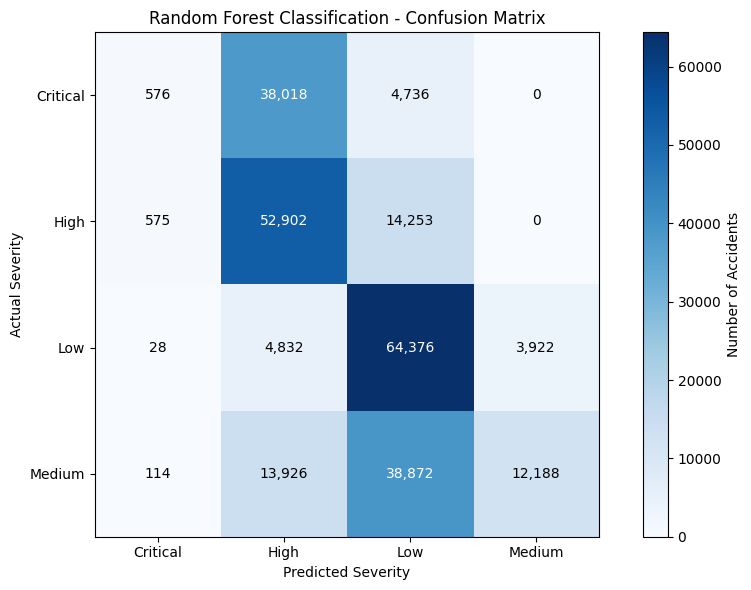

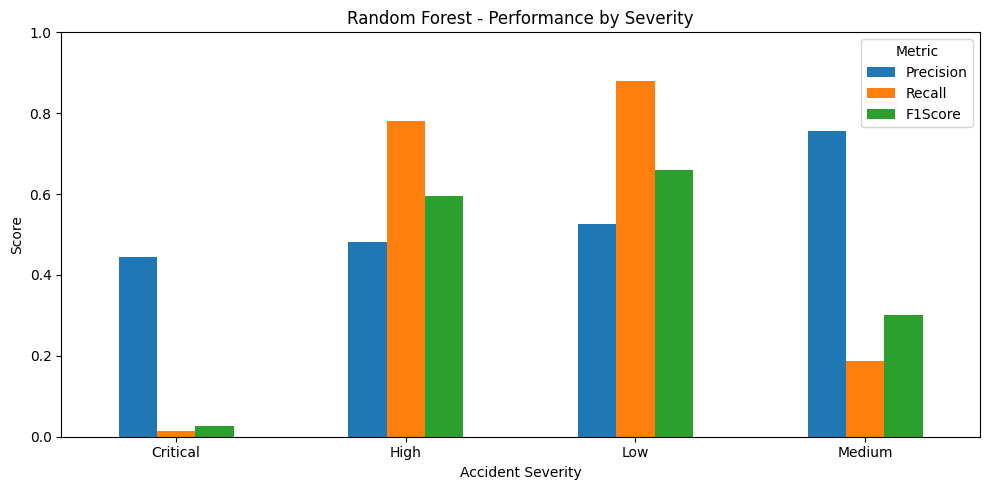

In [0]:

# Task 3 Part A - Cell 30
# Classification Evaluation Visualisations

import matplotlib.pyplot as plt
import numpy as np

# Only four aggregated rows are transferred to pandas
cm_pdf = confusion_matrix_df.toPandas()
metrics_pdf = metrics_df.toPandas()

classes = ["Critical", "High", "Low", "Medium"]

# Build confusion matrix
cm = cm_pdf[
    ["Pred_Critical", "Pred_High",
     "Pred_Low", "Pred_Medium"]
].to_numpy()

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(9, 6))

image = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(4), labels=classes)
ax.set_yticks(range(4), labels=classes)

ax.set_xlabel("Predicted Severity")
ax.set_ylabel("Actual Severity")
ax.set_title("Random Forest Classification - Confusion Matrix")

for i in range(4):
    for j in range(4):
        value = int(cm[i, j])
        ax.text(
            j, i, f"{value:,}",
            ha="center", va="center",
            color="white" if value > cm.max() / 2 else "black"
        )

fig.colorbar(image, ax=ax, label="Number of Accidents")
plt.tight_layout()
plt.show()

# Plot precision, recall and F1 by severity
metrics_pdf = metrics_pdf.set_index("Severity").loc[classes]

ax = metrics_pdf[
    ["Precision", "Recall", "F1Score"]
].plot(kind="bar", figsize=(10, 5))

ax.set_title("Random Forest - Performance by Severity")
ax.set_xlabel("Accident Severity")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric")

plt.tight_layout()
plt.show()


In [0]:

# Task 3 Part A - Cell 31
# Verify chronological separation and establish baseline

from pyspark.sql import functions as F

print("TASK 3 - SPLIT VERIFICATION AND BASELINE")

# Check date ranges for prepared training and testing data
print("\nTRAINING DATE RANGE")
train_prepared.select(
    F.min("AccidentDate").alias("FirstDate"),
    F.max("AccidentDate").alias("LastDate"),
    F.count("*").alias("Records")
).show()

print("\nTESTING DATE RANGE")
test_prepared.select(
    F.min("AccidentDate").alias("FirstDate"),
    F.max("AccidentDate").alias("LastDate"),
    F.count("*").alias("Records")
).show()

# Calculate majority-class baseline from training labels
majority_label = (
    train_prepared.groupBy("label")
    .count()
    .orderBy(F.desc("count"))
    .first()["label"]
)

print("\nMajority class label:", majority_label)

baseline_accuracy = (
    test_prepared
    .filter(F.col("label") == majority_label)
    .count()
    / test_prepared.count()
)

print("Majority-class baseline accuracy:",
      round(baseline_accuracy, 4))

print("Random Forest accuracy: 0.5216")


TASK 3 - SPLIT VERIFICATION AND BASELINE

TRAINING DATE RANGE
+----------+----------+-------+
| FirstDate|  LastDate|Records|
+----------+----------+-------+
|2020-01-01|2022-12-31| 750007|
+----------+----------+-------+


TESTING DATE RANGE
+----------+----------+-------+
| FirstDate|  LastDate|Records|
+----------+----------+-------+
|2023-01-01|2023-12-31| 249318|
+----------+----------+-------+


Majority class label: 2.0
Majority-class baseline accuracy: 0.2934
Random Forest accuracy: 0.5216


In [0]:

# Task 3 Part A - Cell 32
# Time-aware Random Forest hyperparameter tuning

import time
from pyspark.sql import functions as F
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

print("TASK 3 - RANDOM FOREST HYPERPARAMETER TUNING")

# Chronological training/validation split
tuning_train = train_prepared.filter(
    F.col("AccidentDate") < F.lit("2022-01-01")
)

tuning_validation = train_prepared.filter(
    F.col("AccidentDate") >= F.lit("2022-01-01")
)

print("Tuning training records:", tuning_train.count())
print("Validation records:", tuning_validation.count())

# Select by macro F1 to consider all severity classes
# (Spark's 'f1' evaluator is weighted F1, not macro F1)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

parameter_grid = [
    (50, 8),
    (80, 8),
    (50, 12),
    (80, 12)
]

tuning_results = []
best_score = -1
best_params = None

for trees, depth in parameter_grid:
    start = time.time()

    model = RandomForestClassifier(
        labelCol="label",
        featuresCol="features",
        numTrees=trees,
        maxDepth=depth,
        maxBins=64,
        seed=42
    ).fit(tuning_train)

    predictions = model.transform(tuning_validation)

    score = evaluator.evaluate(predictions)
    elapsed = time.time() - start

    tuning_results.append(
        (trees, depth, float(score), round(elapsed, 2))
    )

    print(
        f"Trees={trees}, Depth={depth}, "
        f"Weighted F1={score:.4f}, Time={elapsed:.2f}s"
    )

    if score > best_score:
        best_score = score
        best_params = (trees, depth)

print("\nBest parameters:", best_params)
print("Best validation weighted F1:", round(best_score, 4))

results_df = spark.createDataFrame(
    tuning_results,
    ["NumTrees", "MaxDepth", "ValidationWeightedF1", "TrainingSeconds"]
)

display(results_df.orderBy(F.desc("ValidationWeightedF1")))


TASK 3 - RANDOM FOREST HYPERPARAMETER TUNING
Tuning training records: 499829
Validation records: 250178
Trees=50, Depth=8, Weighted F1=0.4337, Time=77.55s
Trees=80, Depth=8, Weighted F1=0.4414, Time=150.80s
Trees=50, Depth=12, Weighted F1=0.4641, Time=162.20s
Trees=80, Depth=12, Weighted F1=0.4651, Time=287.50s

Best parameters: (80, 12)
Best validation weighted F1: 0.4651


NumTrees,MaxDepth,ValidationWeightedF1,TrainingSeconds
80,12,0.4650574097017232,287.5
50,12,0.4641035088019894,162.2
80,8,0.4413711912961581,150.8
50,8,0.43365969479943867,77.55


In [0]:

# Task 3 Part A - Cell 33
# Final optimised Random Forest classification

import time
from pyspark.sql import functions as F
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

print("TASK 3 - OPTIMISED RANDOM FOREST EVALUATION")

# Selected from Cell 32 validation results
best_trees, best_depth = best_params

optimized_rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=best_trees,
    maxDepth=best_depth,
    maxBins=64,
    seed=42
)

# Retrain on the complete 2020-2022 training period
start_time = time.time()

optimized_rf_model = optimized_rf.fit(train_prepared)

training_time = time.time() - start_time

# Evaluate only on held-out 2023 test records
optimized_predictions = optimized_rf_model.transform(test_prepared)

print("Training completed")
print("Trees:", best_trees)
print("Maximum depth:", best_depth)
print("Training time:", round(training_time, 2), "seconds")

# Evaluate multiple classification metrics
metrics = [
    "accuracy",
    "f1",
    "weightedPrecision",
    "weightedRecall"
]

optimized_scores = {}

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(optimized_predictions)
    optimized_scores[metric] = score

    print(f"{metric}: {score:.4f}")

# Compare with the original Random Forest
print("\nBASELINE RANDOM FOREST VS OPTIMISED")

print("Original accuracy: 0.5216")
print("Optimised accuracy:",
      round(optimized_scores["accuracy"], 4))

print("Original weighted F1: 0.4382")
print("Optimised weighted F1:",
      round(optimized_scores["f1"], 4))

# Display sample predictions
display(
    optimized_predictions.select(
        "severity",
        "label",
        "prediction",
        "probability"
    ).limit(15)
)


TASK 3 - OPTIMISED RANDOM FOREST EVALUATION
Training completed
Trees: 80
Maximum depth: 12
Training time: 384.4 seconds
accuracy: 0.5217
f1: 0.4684
weightedPrecision: 0.5619
weightedRecall: 0.5217

BASELINE RANDOM FOREST VS OPTIMISED
Original accuracy: 0.5216
Optimised accuracy: 0.5217
Original weighted F1: 0.4382
Optimised weighted F1: 0.4684


severity,label,prediction,probability
Critical,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2527283611286871"",""0.7373968276943405"",""0.0058333652259460285"",""0.004041445951026455""]}"
Low,2.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.06342268878163312"",""0.15349157122875334"",""0.49374104049456025"",""0.2893446994950533""]}"
Critical,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.4440711861971942"",""0.4361495871542709"",""0.02948843712651721"",""0.09029078952201777""]}"
Critical,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.24051378707540053"",""0.699819133388569"",""0.03694743987134877"",""0.02271963966468181""]}"
Medium,3.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.07263162826622153"",""0.24117972081169908"",""0.42896913876762177"",""0.25721951215445754""]}"
Medium,3.0,3.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.008251818934968102"",""0.015779371375981614"",""0.24167651981706953"",""0.7342922898719807""]}"
High,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22219172236598891"",""0.40411145242210794"",""0.09355700832774469"",""0.28013981688415857""]}"
High,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.27464709419635136"",""0.48784906861492805"",""0.05551860622925107"",""0.18198523095946936""]}"
Medium,3.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.0791192080208297"",""0.2376637272006016"",""0.4291091167047605"",""0.2541079480738082""]}"
High,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22909272169725048"",""0.40955521178029475"",""0.09066295328539345"",""0.27068911323706135""]}"


In [0]:

# Task 3 Part A - Cell 34
# Original vs optimised per-class performance

from pyspark.sql import functions as F

print("TASK 3 - CLASSIFICATION PERFORMANCE COMPARISON")

severity_mapping = {
    0: "Critical",
    1: "High",
    2: "Low",
    3: "Medium"
}

def class_metrics(predictions, model_name):
    # Aggregate once rather than repeatedly scanning predictions
    counts = (
        predictions
        .groupBy("label", "prediction")
        .count()
        .collect()
    )

    matrix = {
        (int(row["label"]), int(row["prediction"])): row["count"]
        for row in counts
    }

    results = []

    for label, severity in severity_mapping.items():
        tp = matrix.get((label, label), 0)

        actual = sum(
            matrix.get((label, p), 0)
            for p in severity_mapping
        )

        predicted = sum(
            matrix.get((a, label), 0)
            for a in severity_mapping
        )

        precision = tp / predicted if predicted else 0.0
        recall = tp / actual if actual else 0.0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        results.append((
            model_name,
            severity,
            actual,
            float(precision),
            float(recall),
            float(f1)
        ))

    return results, matrix

# rf_predictions is the original model output from Cell 29
original_results, original_matrix = class_metrics(
    rf_predictions, "Original"
)

optimized_results, optimized_matrix = class_metrics(
    optimized_predictions, "Optimised"
)

comparison_df = spark.createDataFrame(
    original_results + optimized_results,
    ["Model", "Severity", "Support",
     "Precision", "Recall", "F1Score"]
)

print("\nPER-CLASS PERFORMANCE")
display(comparison_df.orderBy("Severity", "Model"))

# Compare Critical recall directly
original_critical = next(
    r for r in original_results if r[1] == "Critical"
)

optimized_critical = next(
    r for r in optimized_results if r[1] == "Critical"
)

print("\nCRITICAL ACCIDENT DETECTION")
print(
    "Original Critical recall:",
    round(original_critical[4], 4)
)
print(
    "Optimised Critical recall:",
    round(optimized_critical[4], 4)
)
print(
    "Critical recall change:",
    round(optimized_critical[4] - original_critical[4], 4)
)

# Display readable optimised confusion matrix
matrix_rows = []

for actual_label, actual_name in severity_mapping.items():
    matrix_rows.append((
        actual_name,
        *[
            int(optimized_matrix.get((actual_label, p), 0))
            for p in severity_mapping
        ]
    ))

matrix_df = spark.createDataFrame(
    matrix_rows,
    ["ActualSeverity", "Pred_Critical",
     "Pred_High", "Pred_Low", "Pred_Medium"]
)

print("\nOPTIMISED CONFUSION MATRIX")
display(matrix_df)


TASK 3 - CLASSIFICATION PERFORMANCE COMPARISON

PER-CLASS PERFORMANCE


Model,Severity,Support,Precision,Recall,F1Score
Optimised,Critical,43330,0.44382509599900904,0.16538195245788137,0.24097114802609457
Original,Critical,43330,0.44547563805104406,0.013293330256173552,0.02581628308271519
Optimised,High,67730,0.48855259688900604,0.6839952753580393,0.569985543354557
Original,High,67730,0.4823392111453528,0.7810719031448398,0.596387987012987
Optimised,Low,73158,0.5266490506147893,0.8799584461029553,0.6589319071624147
Original,Low,73158,0.5266490506147893,0.8799584461029553,0.6589319071624147
Optimised,Medium,65100,0.7565487274984481,0.18721966205837173,0.3001600788080286
Original,Medium,65100,0.7565487274984481,0.18721966205837173,0.3001600788080286



CRITICAL ACCIDENT DETECTION
Original Critical recall: 0.0133
Optimised Critical recall: 0.1654
Critical recall change: 0.1521

OPTIMISED CONFUSION MATRIX


ActualSeverity,Pred_Critical,Pred_High,Pred_Low,Pred_Medium
Critical,7166,31428,4736,0
High,7150,46327,14253,0
Low,479,4381,64376,3922
Medium,1351,12689,38872,12188


TASK 3 - CLASSIFICATION OPTIMISATION VISUALISATION


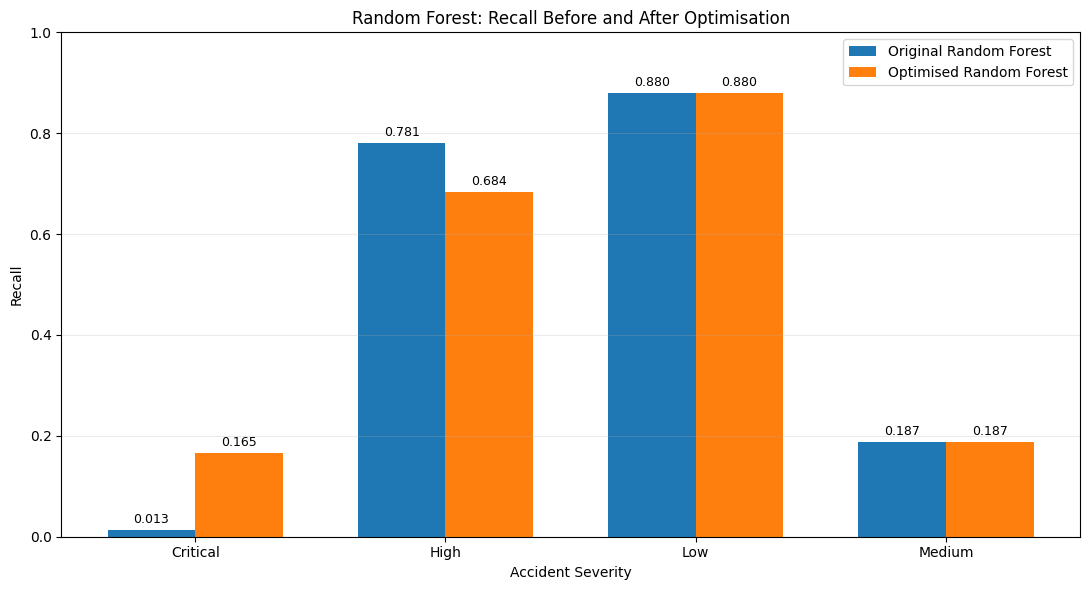

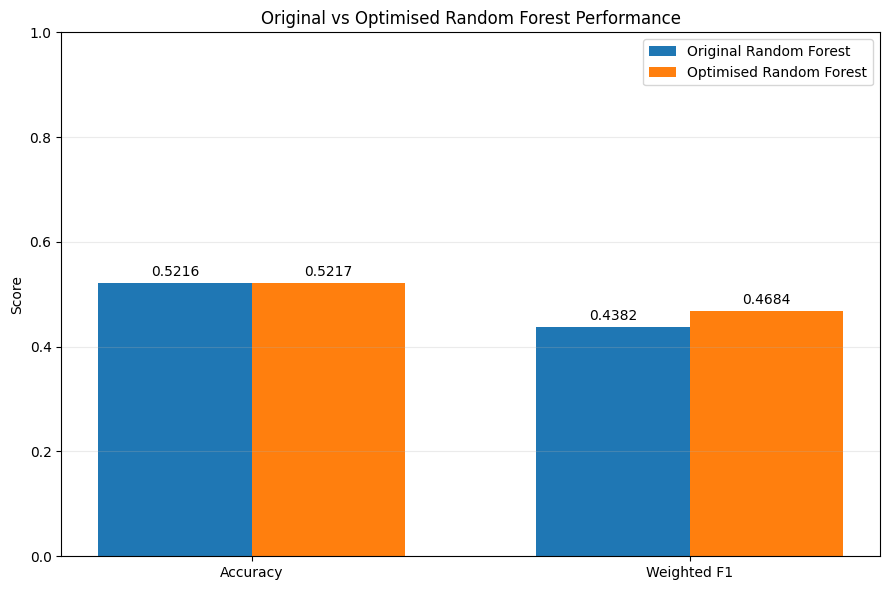


FINAL CLASSIFICATION COMPARISON
Original Accuracy: 0.5216
Optimised Accuracy: 0.5217
Original Weighted F1: 0.4382
Optimised Weighted F1: 0.4684
Critical Recall Before: 0.0133
Critical Recall After: 0.1654
Critical Recall Improvement: 0.1521

Cell 35 visualisation completed successfully.


In [0]:

# ============================================================
# Task 3 Part A - Cell 35
# Original vs Optimised Random Forest Visualisation
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

print("TASK 3 - CLASSIFICATION OPTIMISATION VISUALISATION")

# ------------------------------------------------------------
# STEP 1: Extract per-class recall from Cell 34
# ------------------------------------------------------------

severity_order = ["Critical", "High", "Low", "Medium"]

original_recall = {
    row[1]: row[4] for row in original_results
}

optimized_recall = {
    row[1]: row[4] for row in optimized_results
}

original_recall_values = [
    original_recall[s] for s in severity_order
]

optimized_recall_values = [
    optimized_recall[s] for s in severity_order
]

# ------------------------------------------------------------
# STEP 2: Chart 1 - Recall comparison by severity
# ------------------------------------------------------------

x = np.arange(len(severity_order))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    original_recall_values,
    width,
    label="Original Random Forest"
)

bars2 = ax.bar(
    x + width / 2,
    optimized_recall_values,
    width,
    label="Optimised Random Forest"
)

ax.set_xticks(x)
ax.set_xticklabels(severity_order)
ax.set_xlabel("Accident Severity")
ax.set_ylabel("Recall")
ax.set_title(
    "Random Forest: Recall Before and After Optimisation"
)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 3: Prepare overall classification metrics
# ------------------------------------------------------------

# Verified values from your original and optimised
# Random Forest evaluation outputs

metrics = ["Accuracy", "Weighted F1"]

original_chart_values = [
    0.5216,
    0.4382
]

optimized_chart_values = [
    0.5217,
    0.4684
]

# Separate variable names prevent overwriting
# the optimized_scores dictionary from Cell 33.

# ------------------------------------------------------------
# STEP 4: Chart 2 - Overall model performance
# ------------------------------------------------------------

x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width / 2,
    original_chart_values,
    width,
    label="Original Random Forest"
)

bars2 = ax.bar(
    x + width / 2,
    optimized_chart_values,
    width,
    label="Optimised Random Forest"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score")
ax.set_title(
    "Original vs Optimised Random Forest Performance"
)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# STEP 5: Print final verified comparison
# ------------------------------------------------------------

print("\nFINAL CLASSIFICATION COMPARISON")

print("Original Accuracy: 0.5216")
print("Optimised Accuracy: 0.5217")

print("Original Weighted F1: 0.4382")
print("Optimised Weighted F1: 0.4684")

print(
    "Critical Recall Before:",
    round(original_recall["Critical"], 4)
)

print(
    "Critical Recall After:",
    round(optimized_recall["Critical"], 4)
)

print(
    "Critical Recall Improvement:",
    round(
        optimized_recall["Critical"]
        - original_recall["Critical"],
        4
    )
)

print("\nCell 35 visualisation completed successfully.")


In [0]:

# ============================================================
# Task 3 Part A - Cell 36
# Time-Series Forecasting: Data Preparation and Verification
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window

print("TASK 3 - TIME-SERIES FORECASTING DATA PREPARATION")

# STEP 1: Use the validated complete-month dataset
forecast_df = (
    complete_months_df
    .withColumn(
        "MonthDate",
        F.to_date(
            F.concat(F.col("YearMonth"), F.lit("-01"))
        )
    )
    .select(
        "MonthDate",
        F.col("MonthlyAccidents").cast("long")
    )
    .orderBy("MonthDate")
)

# STEP 2: Verify the time-series dataset
print("\nTOTAL MONTHLY OBSERVATIONS:", forecast_df.count())

forecast_df.agg(
    F.min("MonthDate").alias("FirstMonth"),
    F.max("MonthDate").alias("LastMonth"),
    F.sum("MonthlyAccidents").alias("TotalAccidents")
).show()

print("\nMONTHLY DATASET")
display(forecast_df)

# STEP 3: Create chronological training and testing sets
forecast_train = forecast_df.filter(
    F.col("MonthDate") < F.lit("2023-01-01")
)

forecast_test = forecast_df.filter(
    (F.col("MonthDate") >= F.lit("2023-01-01")) &
    (F.col("MonthDate") < F.lit("2024-01-01"))
)

print("\nTRAINING MONTHS:", forecast_train.count())
print("TESTING MONTHS:", forecast_test.count())

print("\nTRAINING DATE RANGE")
forecast_train.agg(
    F.min("MonthDate").alias("FirstMonth"),
    F.max("MonthDate").alias("LastMonth")
).show()

print("\nTESTING DATE RANGE")
forecast_test.agg(
    F.min("MonthDate").alias("FirstMonth"),
    F.max("MonthDate").alias("LastMonth")
).show()

# STEP 4: Check for missing calendar months
expected_months = (
    (2023 - 2020 + 1) * 12
)

actual_months = forecast_df.count()

print("\nEXPECTED MONTHS:", expected_months)
print("ACTUAL MONTHS:", actual_months)
print("MONTH COUNT MATCHES:", actual_months == expected_months)

# Check for duplicate months
duplicate_months = (
    forecast_df
    .groupBy("MonthDate")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("DUPLICATE MONTHS:", duplicate_months)

# Verify every month in the expected date range exists
calendar_df = spark.sql("""
    SELECT explode(
        sequence(
            DATE '2020-01-01',
            DATE '2023-12-01',
            INTERVAL 1 MONTH
        )
    ) AS MonthDate
""")

missing_months = calendar_df.join(
    forecast_df.select("MonthDate"),
    on="MonthDate",
    how="left_anti"
)

print("MISSING CALENDAR MONTHS:", missing_months.count())

print("\nCELL 36 COMPLETED")


TASK 3 - TIME-SERIES FORECASTING DATA PREPARATION

TOTAL MONTHLY OBSERVATIONS: 48
+----------+----------+--------------+
|FirstMonth| LastMonth|TotalAccidents|
+----------+----------+--------------+
|2020-01-01|2023-12-01|        999325|
+----------+----------+--------------+


MONTHLY DATASET


MonthDate,MonthlyAccidents
2020-01-01,21116
2020-02-01,19817
2020-03-01,21160
2020-04-01,20477
2020-05-01,20986
2020-06-01,20439
2020-07-01,21209
2020-08-01,21237
2020-09-01,20526
2020-10-01,21485



TRAINING MONTHS: 36
TESTING MONTHS: 12

TRAINING DATE RANGE
+----------+----------+
|FirstMonth| LastMonth|
+----------+----------+
|2020-01-01|2022-12-01|
+----------+----------+


TESTING DATE RANGE
+----------+----------+
|FirstMonth| LastMonth|
+----------+----------+
|2023-01-01|2023-12-01|
+----------+----------+


EXPECTED MONTHS: 48
ACTUAL MONTHS: 48
MONTH COUNT MATCHES: True
DUPLICATE MONTHS: 0
MISSING CALENDAR MONTHS: 0

CELL 36 COMPLETED


In [0]:

# ============================================================
# Task 3 Part A - Cell 37
# Seasonal Naive Baseline Forecasting
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window
import math

print("TASK 3 - SEASONAL NAIVE BASELINE FORECASTING")

# STEP 1: Create seasonal predictions using the
# corresponding month from the previous year.

baseline_history = (
    forecast_train
    .select(
        F.add_months(F.col("MonthDate"), 12).alias("MonthDate"),
        F.col("MonthlyAccidents").cast("double").alias("Prediction")
    )
)

# STEP 2: Match predictions against actual test observations.
baseline_predictions = (
    forecast_test
    .join(baseline_history, on="MonthDate", how="left")
    .select(
        "MonthDate",
        F.col("MonthlyAccidents").cast("double").alias("Actual"),
        "Prediction"
    )
    .orderBy("MonthDate")
)

print("\nBASELINE PREDICTIONS")
display(baseline_predictions)

# STEP 3: Validate predictions.
missing_predictions = baseline_predictions.filter(
    F.col("Prediction").isNull()
).count()

print("\nTEST MONTHS:", baseline_predictions.count())
print("MISSING PREDICTIONS:", missing_predictions)

assert missing_predictions == 0, "Missing baseline predictions detected."

# STEP 4: Calculate forecasting errors.
baseline_errors = (
    baseline_predictions
    .withColumn("AbsoluteError", F.abs(F.col("Actual") - F.col("Prediction")))
    .withColumn("SquaredError", F.pow(F.col("Actual") - F.col("Prediction"), 2))
    .withColumn(
        "AbsolutePercentageError",
        F.when(
            F.col("Actual") != 0,
            F.abs(F.col("Actual") - F.col("Prediction")) /
            F.abs(F.col("Actual")) * 100
        )
    )
)

# STEP 5: Evaluate MAE, RMSE and MAPE.
baseline_metrics = baseline_errors.agg(
    F.avg("AbsoluteError").alias("MAE"),
    F.sqrt(F.avg("SquaredError")).alias("RMSE"),
    F.avg("AbsolutePercentageError").alias("MAPE")
).first()

baseline_mae = float(baseline_metrics["MAE"])
baseline_rmse = float(baseline_metrics["RMSE"])
baseline_mape = float(baseline_metrics["MAPE"])

print("\nSEASONAL NAIVE BASELINE PERFORMANCE")
print(f"MAE: {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"MAPE: {baseline_mape:.2f}%")

print("\nMONTHLY FORECAST ERRORS")
display(baseline_errors)

print("\nCELL 37 COMPLETED SUCCESSFULLY")


TASK 3 - SEASONAL NAIVE BASELINE FORECASTING

BASELINE PREDICTIONS


MonthDate,Actual,Prediction
2023-01-01,21400.0,21158.0
2023-02-01,19056.0,19291.0
2023-03-01,21194.0,20932.0
2023-04-01,20538.0,20802.0
2023-05-01,21092.0,21357.0
2023-06-01,20513.0,20523.0
2023-07-01,21037.0,21161.0
2023-08-01,21355.0,21288.0
2023-09-01,20271.0,20762.0
2023-10-01,21048.0,21096.0


Databricks visualization. Run in Databricks to view.


TEST MONTHS: 12
MISSING PREDICTIONS: 0

SEASONAL NAIVE BASELINE PERFORMANCE
MAE: 182.67
RMSE: 224.10
MAPE: 0.89%

MONTHLY FORECAST ERRORS


MonthDate,Actual,Prediction,AbsoluteError,SquaredError,AbsolutePercentageError
2023-01-01,21400.0,21158.0,242.0,58564.0,1.1308411214953271
2023-02-01,19056.0,19291.0,235.0,55225.0,1.2332073887489505
2023-03-01,21194.0,20932.0,262.0,68644.0,1.236198924223837
2023-04-01,20538.0,20802.0,264.0,69696.0,1.2854221443178497
2023-05-01,21092.0,21357.0,265.0,70225.0,1.256400531007017
2023-06-01,20513.0,20523.0,10.0,100.0,0.04874957344123239
2023-07-01,21037.0,21161.0,124.0,15376.0,0.5894376574606645
2023-08-01,21355.0,21288.0,67.0,4489.0,0.3137438538983845
2023-09-01,20271.0,20762.0,491.0,241081.0,2.4221794682058113
2023-10-01,21048.0,21096.0,48.0,2304.0,0.22805017103762829



CELL 37 COMPLETED SUCCESSFULLY


In [0]:

# ============================================================
# Task 3 Part A - Cell 38
# Time-Series Feature Engineering
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window

print("TASK 3 - FORECASTING FEATURE ENGINEERING")

# Chronological ordering
time_window = Window.orderBy("MonthDate")

# Historical observations only
lag_features_df = (
    forecast_df
    .withColumn(
        "Lag1",
        F.lag("MonthlyAccidents", 1).over(time_window)
    )
    .withColumn(
        "Lag2",
        F.lag("MonthlyAccidents", 2).over(time_window)
    )
    .withColumn(
        "Lag3",
        F.lag("MonthlyAccidents", 3).over(time_window)
    )
    .withColumn(
        "Lag12",
        F.lag("MonthlyAccidents", 12).over(time_window)
    )
    .withColumn(
        "RollingMean3",
        F.avg("MonthlyAccidents").over(
            time_window.rowsBetween(-3, -1)
        )
    )
    .withColumn(
        "Month",
        F.month("MonthDate")
    )
    .withColumn(
        "Year",
        F.year("MonthDate")
    )
)

# Remove months without sufficient historical observations
forecast_features_df = lag_features_df.dropna(
    subset=["Lag1", "Lag2", "Lag3", "Lag12", "RollingMean3"]
)

print("\nFEATURE-ENGINEERED DATASET")
print("Total observations:", forecast_features_df.count())

display(forecast_features_df.orderBy("MonthDate"))

# Chronological training and testing split
forecast_ml_train = forecast_features_df.filter(
    F.col("MonthDate") < F.lit("2023-01-01")
)

forecast_ml_test = forecast_features_df.filter(
    (F.col("MonthDate") >= F.lit("2023-01-01")) &
    (F.col("MonthDate") < F.lit("2024-01-01"))
)

print("\nTRAINING OBSERVATIONS:", forecast_ml_train.count())
print("TESTING OBSERVATIONS:", forecast_ml_test.count())

print("\nTRAINING DATE RANGE")
forecast_ml_train.agg(
    F.min("MonthDate").alias("FirstMonth"),
    F.max("MonthDate").alias("LastMonth")
).show()

print("\nTESTING DATE RANGE")
forecast_ml_test.agg(
    F.min("MonthDate").alias("FirstMonth"),
    F.max("MonthDate").alias("LastMonth")
).show()

print("\nCELL 38 COMPLETED SUCCESSFULLY")


TASK 3 - FORECASTING FEATURE ENGINEERING

FEATURE-ENGINEERED DATASET


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Total observations: 36


MonthDate,MonthlyAccidents,Lag1,Lag2,Lag3,Lag12,RollingMean3,Month,Year
2021-01-01,21256,21304,20685,21485,21116,21158.0,1,2021
2021-02-01,19100,21256,21304,20685,19817,21081.666666666668,2,2021
2021-03-01,21010,19100,21256,21304,21160,20553.333333333332,3,2021
2021-04-01,20633,21010,19100,21256,20477,20455.333333333332,4,2021
2021-05-01,21284,20633,21010,19100,20986,20247.666666666668,5,2021
2021-06-01,20439,21284,20633,21010,20439,20975.666666666668,6,2021
2021-07-01,20961,20439,21284,20633,21209,20785.333333333332,7,2021
2021-08-01,20977,20961,20439,21284,21237,20894.666666666668,8,2021
2021-09-01,20528,20977,20961,20439,20526,20792.333333333332,9,2021
2021-10-01,21358,20528,20977,20961,21485,20822.0,10,2021



TRAINING OBSERVATIONS: 24
TESTING OBSERVATIONS: 12

TRAINING DATE RANGE
+----------+----------+
|FirstMonth| LastMonth|
+----------+----------+
|2021-01-01|2022-12-01|
+----------+----------+


TESTING DATE RANGE
+----------+----------+
|FirstMonth| LastMonth|
+----------+----------+
|2023-01-01|2023-12-01|
+----------+----------+


CELL 38 COMPLETED SUCCESSFULLY


In [0]:

# ============================================================
# Task 3 Part A - Cell 39
# Random Forest Regression Training
# ============================================================

import time

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml import Pipeline
from pyspark.sql import functions as F

print("TASK 3 - RANDOM FOREST FORECASTING MODEL TRAINING")

# STEP 1: Define forecasting input features
forecast_feature_cols = [
    "Lag1",
    "Lag2",
    "Lag3",
    "Lag12",
    "RollingMean3",
    "Month"
]

# STEP 2: Assemble numerical features
forecast_assembler = VectorAssembler(
    inputCols=forecast_feature_cols,
    outputCol="features",
    handleInvalid="error"
)

# STEP 3: Configure Random Forest Regressor
forecast_rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="MonthlyAccidents",
    predictionCol="prediction",
    numTrees=50,
    maxDepth=5,
    seed=42
)

# STEP 4: Build the ML pipeline
forecast_pipeline = Pipeline(
    stages=[forecast_assembler, forecast_rf]
)

# STEP 5: Train using historical data only
start_time = time.time()

forecast_rf_model = forecast_pipeline.fit(forecast_ml_train)

training_time = time.time() - start_time

# STEP 6: Generate one-month-ahead test predictions
forecast_rf_predictions = forecast_rf_model.transform(
    forecast_ml_test
)

# STEP 7: Display prediction results
print("\nMODEL TRAINING COMPLETED")
print(f"Training time: {training_time:.2f} seconds")

print("\nMODEL CONFIGURATION")
print("Algorithm: Random Forest Regressor")
print("Number of trees: 50")
print("Maximum depth: 5")
print("Random seed: 42")
print("Input features:", forecast_feature_cols)

print("\nFORECASTING PREDICTIONS")

display(
    forecast_rf_predictions
    .select(
        "MonthDate",
        F.col("MonthlyAccidents").alias("Actual"),
        F.round("prediction", 2).alias("Predicted")
    )
    .orderBy("MonthDate")
)

print("\nTRAINING OBSERVATIONS:", forecast_ml_train.count())
print("TESTING OBSERVATIONS:", forecast_ml_test.count())

print("\nCELL 39 COMPLETED SUCCESSFULLY")


TASK 3 - RANDOM FOREST FORECASTING MODEL TRAINING


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(



MODEL TRAINING COMPLETED
Training time: 2.90 seconds

MODEL CONFIGURATION
Algorithm: Random Forest Regressor
Number of trees: 50
Maximum depth: 5
Random seed: 42
Input features: ['Lag1', 'Lag2', 'Lag3', 'Lag12', 'RollingMean3', 'Month']

FORECASTING PREDICTIONS


MonthDate,Actual,Predicted
2023-01-01,21400,20844.49
2023-02-01,19056,19542.16
2023-03-01,21194,21042.18
2023-04-01,20538,20862.55
2023-05-01,21092,21186.93
2023-06-01,20513,20650.58
2023-07-01,21037,21202.34
2023-08-01,21355,20923.27
2023-09-01,20271,20735.81
2023-10-01,21048,21096.5



TRAINING OBSERVATIONS: 24
TESTING OBSERVATIONS: 12

CELL 39 COMPLETED SUCCESSFULLY


In [0]:

# ============================================================
# Task 3 Part A - Cell 40
# Random Forest Forecast Evaluation
# ============================================================

from pyspark.sql import functions as F

print("TASK 3 - RANDOM FOREST FORECAST EVALUATION")

# STEP 1: Prepare actual and predicted values
rf_forecast_results = (
    forecast_rf_predictions
    .select(
        "MonthDate",
        F.col("MonthlyAccidents").cast("double").alias("Actual"),
        F.col("prediction").cast("double").alias("Prediction")
    )
    .orderBy("MonthDate")
)

# STEP 2: Calculate forecasting errors
rf_forecast_errors = (
    rf_forecast_results
    .withColumn(
        "AbsoluteError",
        F.abs(F.col("Actual") - F.col("Prediction"))
    )
    .withColumn(
        "SquaredError",
        F.pow(F.col("Actual") - F.col("Prediction"), 2)
    )
    .withColumn(
        "AbsolutePercentageError",
        F.when(
            F.col("Actual") != 0,
            F.abs(F.col("Actual") - F.col("Prediction")) /
            F.abs(F.col("Actual")) * 100
        )
    )
)

# STEP 3: Calculate evaluation metrics
rf_metrics = rf_forecast_errors.agg(
    F.avg("AbsoluteError").alias("MAE"),
    F.sqrt(F.avg("SquaredError")).alias("RMSE"),
    F.avg("AbsolutePercentageError").alias("MAPE")
).first()

rf_mae = float(rf_metrics["MAE"])
rf_rmse = float(rf_metrics["RMSE"])
rf_mape = float(rf_metrics["MAPE"])

print("\nRANDOM FOREST PERFORMANCE")
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"MAPE: {rf_mape:.2f}%")

# STEP 4: Compare with seasonal naive baseline
comparison_data = [
    ("Seasonal Naive", baseline_mae, baseline_rmse, baseline_mape),
    ("Random Forest", rf_mae, rf_rmse, rf_mape)
]

forecast_comparison_df = spark.createDataFrame(
    comparison_data,
    ["Model", "MAE", "RMSE", "MAPE"]
)

print("\nBASELINE VS RANDOM FOREST")
display(forecast_comparison_df)

# STEP 5: Calculate relative improvements
mae_improvement = (
    (baseline_mae - rf_mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - rf_rmse) / baseline_rmse
) * 100

print("\nRELATIVE PERFORMANCE CHANGE")
print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

if rf_mae < baseline_mae:
    print("Random Forest outperforms the baseline on MAE.")
else:
    print("Seasonal Naive performs better on MAE.")

# STEP 6: Display individual forecast errors
print("\nMONTHLY FORECAST ERRORS")
display(rf_forecast_errors)

print("\nCELL 40 COMPLETED SUCCESSFULLY")


TASK 3 - RANDOM FOREST FORECAST EVALUATION


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(



RANDOM FOREST PERFORMANCE
MAE: 262.84
RMSE: 318.39
MAPE: 1.28%

BASELINE VS RANDOM FOREST


Model,MAE,RMSE,MAPE
Seasonal Naive,182.66666666666666,224.10005206008617,0.8854261760161025
Random Forest,262.8425674603165,318.38633088926105,1.2768690397425297



RELATIVE PERFORMANCE CHANGE
MAE improvement: -43.89%
RMSE improvement: -42.07%
Seasonal Naive performs better on MAE.

MONTHLY FORECAST ERRORS


MonthDate,Actual,Prediction,AbsoluteError,SquaredError,AbsolutePercentageError
2023-01-01,21400.0,20844.48904761905,555.5109523809515,308592.41821519175,2.595845571873605
2023-02-01,19056.0,19542.16,486.15999999999985,236351.54559999987,2.5512174643157004
2023-03-01,21194.0,21042.176,151.82400000000052,23050.526976000157,0.7163536850051926
2023-04-01,20538.0,20862.551428571423,324.55142857142346,105333.62978775178,1.5802484593018962
2023-05-01,21092.0,21186.930333333334,94.93033333333369,9011.768186777846,0.45007743852329646
2023-06-01,20513.0,20650.57976190476,137.57976190475893,18928.190885770156,0.6706954707003311
2023-07-01,21037.0,21202.34342857143,165.34342857142838,27338.449371755036,0.7859648646262698
2023-08-01,21355.0,20923.267428571427,431.73257142857256,186393.0132323275,2.0216931464695507
2023-09-01,20271.0,20735.81442857143,464.81442857142974,216052.45300818476,2.2930019662149363
2023-10-01,21048.0,21096.501904761903,48.50190476190255,2352.4347655326656,0.23043474326255486



CELL 40 COMPLETED SUCCESSFULLY


In [0]:

# ============================================================
# Task 3 Part A - Cell 41
# Random Forest Regression Hyperparameter Tuning
# ========================================================

import time

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

print("TASK 3 - FORECASTING HYPERPARAMETER TUNING")

# Chronological validation:
# Train: January 2021 to June 2022 (18 months)
# Validate: July 2022 to December 2022 (6 months)

tuning_train = forecast_ml_train.filter(
    F.col("MonthDate") < F.lit("2022-07-01")
)

tuning_validation = forecast_ml_train.filter(
    F.col("MonthDate") >= F.lit("2022-07-01")
)

print("Tuning training months:", tuning_train.count())
print("Validation months:", tuning_validation.count())

assert tuning_train.count() == 18
assert tuning_validation.count() == 6

feature_cols = [
    "Lag1", "Lag2", "Lag3",
    "Lag12", "RollingMean3", "Month"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

evaluator = RegressionEvaluator(
    labelCol="MonthlyAccidents",
    predictionCol="prediction",
    metricName="rmse"
)

# Candidate hyperparameters
parameter_grid = [
    (30, 3),
    (50, 3),
    (50, 5),
    (80, 5),
    (80, 7),
    (100, 7)
]

tuning_results = []

for trees, depth in parameter_grid:

    start = time.time()

    rf = RandomForestRegressor(
        featuresCol="features",
        labelCol="MonthlyAccidents",
        predictionCol="prediction",
        numTrees=trees,
        maxDepth=depth,
        seed=42
    )

    pipeline = Pipeline(stages=[assembler, rf])

    model = pipeline.fit(tuning_train)

    predictions = model.transform(tuning_validation)

    rmse = evaluator.evaluate(predictions)

    elapsed = time.time() - start

    tuning_results.append(
        (trees, depth, float(rmse), float(elapsed))
    )

    print(
        f"Trees={trees}, Depth={depth}, "
        f"Validation RMSE={rmse:.2f}, "
        f"Time={elapsed:.2f}s"
    )

# Convert results into a Spark DataFrame
tuning_results_df = spark.createDataFrame(
    tuning_results,
    ["NumTrees", "MaxDepth", "ValidationRMSE", "TrainingSeconds"]
)

print("\nHYPERPARAMETER TUNING RESULTS")

display(
    tuning_results_df.orderBy("ValidationRMSE")
)

# Select best configuration
best_result = min(
    tuning_results,
    key=lambda row: row[2]
)

best_trees = best_result[0]
best_depth = best_result[1]
best_validation_rmse = best_result[2]

print("\nBEST PARAMETERS")
print("Number of trees:", best_trees)
print("Maximum depth:", best_depth)
print(f"Validation RMSE: {best_validation_rmse:.2f}")

print("\nCELL 41 COMPLETED SUCCESSFULLY")


TASK 3 - FORECASTING HYPERPARAMETER TUNING


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Tuning training months: 18
Validation months: 6
Trees=30, Depth=3, Validation RMSE=305.92, Time=9.11s
Trees=50, Depth=3, Validation RMSE=311.98, Time=5.76s
Trees=50, Depth=5, Validation RMSE=318.77, Time=8.14s
Trees=80, Depth=5, Validation RMSE=294.89, Time=9.20s
Trees=80, Depth=7, Validation RMSE=295.36, Time=12.92s
Trees=100, Depth=7, Validation RMSE=387.24, Time=13.21s

HYPERPARAMETER TUNING RESULTS


NumTrees,MaxDepth,ValidationRMSE,TrainingSeconds
80,5,294.88832529561495,9.197344541549683
80,7,295.3622250574459,12.9188551902771
30,3,305.92102029022817,9.112296342849731
50,3,311.9791212148981,5.762146472930908
50,5,318.7711488100903,8.135077238082886
100,7,387.23653910153314,13.20786738395691



BEST PARAMETERS
Number of trees: 80
Maximum depth: 5
Validation RMSE: 294.89

CELL 41 COMPLETED SUCCESSFULLY


In [0]:
import time

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor

print("TASK 3 - OPTIMISED FORECASTING MODEL EVALUATION")

# STEP 1: Configure the selected model
optimized_forecast_rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="MonthlyAccidents",
    predictionCol="prediction",
    numTrees=best_trees,
    maxDepth=best_depth,
    seed=42
)

optimized_forecast_pipeline = Pipeline(
    stages=[
        VectorAssembler(
            inputCols=forecast_feature_cols,
            outputCol="features"
        ),
        optimized_forecast_rf
    ]
)

# STEP 2: Retrain on all 24 historical training months
start_time = time.time()

optimized_forecast_model = optimized_forecast_pipeline.fit(
    forecast_ml_train
)

optimized_training_time = time.time() - start_time

# STEP 3: Generate predictions for 2023
optimized_forecast_predictions = (
    optimized_forecast_model
    .transform(forecast_ml_test)
    .select(
        "MonthDate",
        F.col("MonthlyAccidents").cast("double").alias("Actual"),
        F.col("prediction").cast("double").alias("Prediction")
    )
    .orderBy("MonthDate")
)

# STEP 4: Calculate errors
optimized_forecast_errors = (
    optimized_forecast_predictions
    .withColumn(
        "AbsoluteError",
        F.abs(F.col("Actual") - F.col("Prediction"))
    )
    .withColumn(
        "SquaredError",
        F.pow(F.col("Actual") - F.col("Prediction"), 2)
    )
    .withColumn(
        "AbsolutePercentageError",
        F.when(
            F.col("Actual") != 0,
            F.abs(F.col("Actual") - F.col("Prediction")) /
            F.abs(F.col("Actual")) * 100
        )
    )
)

# STEP 5: Calculate evaluation metrics
optimized_metrics = optimized_forecast_errors.agg(
    F.avg("AbsoluteError").alias("MAE"),
    F.sqrt(F.avg("SquaredError")).alias("RMSE"),
    F.avg("AbsolutePercentageError").alias("MAPE")
).first()

optimized_mae = float(optimized_metrics["MAE"])
optimized_rmse = float(optimized_metrics["RMSE"])
optimized_mape = float(optimized_metrics["MAPE"])

print("\nOPTIMISED MODEL CONFIGURATION")
print("Trees:", best_trees)
print("Maximum depth:", best_depth)
print(f"Training time: {optimized_training_time:.2f} seconds")

print("\nOPTIMISED FORECASTING PERFORMANCE")
print(f"MAE: {optimized_mae:.2f}")
print(f"RMSE: {optimized_rmse:.2f}")
print(f"MAPE: {optimized_mape:.2f}%")

# STEP 6: Compare all three models
final_forecast_comparison = spark.createDataFrame(
    [
        ("Seasonal Naive", baseline_mae, baseline_rmse, baseline_mape),
        ("Original Random Forest", rf_mae, rf_rmse, rf_mape),
        ("Optimised Random Forest", optimized_mae, optimized_rmse, optimized_mape)
    ],
    ["Model", "MAE", "RMSE", "MAPE"]
)

print("\nFINAL FORECASTING MODEL COMPARISON")
display(final_forecast_comparison.orderBy("RMSE"))

# STEP 7: Display optimized predictions
print("\nOPTIMISED MONTHLY PREDICTIONS")
display(optimized_forecast_predictions)

print("\nCELL 42 COMPLETED SUCCESSFULLY")


TASK 3 - OPTIMISED FORECASTING MODEL EVALUATION


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(



OPTIMISED MODEL CONFIGURATION
Trees: 80
Maximum depth: 5
Training time: 2.14 seconds

OPTIMISED FORECASTING PERFORMANCE
MAE: 274.93
RMSE: 339.15
MAPE: 1.34%

FINAL FORECASTING MODEL COMPARISON


Model,MAE,RMSE,MAPE
Seasonal Naive,182.66666666666666,224.10005206008617,0.8854261760161025
Original Random Forest,262.8425674603165,318.38633088926105,1.2768690397425297
Optimised Random Forest,274.92748545725044,339.14657037788,1.3418336868900367



OPTIMISED MONTHLY PREDICTIONS


MonthDate,Actual,Prediction
2023-01-01,21400.0,20830.13166666667
2023-02-01,19056.0,19714.659375
2023-03-01,21194.0,21035.09160714286
2023-04-01,20538.0,20894.49404401155
2023-05-01,21092.0,21163.239136904762
2023-06-01,20513.0,20709.09976325757
2023-07-01,21037.0,21166.036626984125
2023-08-01,21355.0,20994.14634424603
2023-09-01,20271.0,20752.980664682542
2023-10-01,21048.0,21117.43404761905



CELL 42 COMPLETED SUCCESSFULLY


TASK 3 - FINAL FORECASTING VISUALISATION


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(
/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


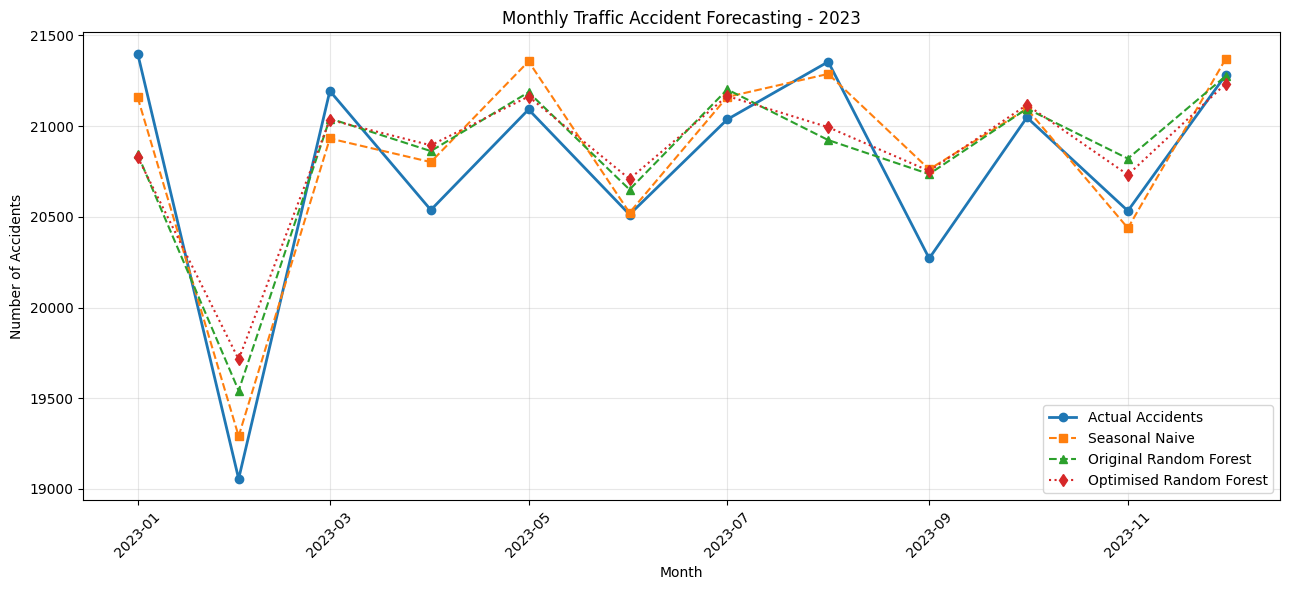

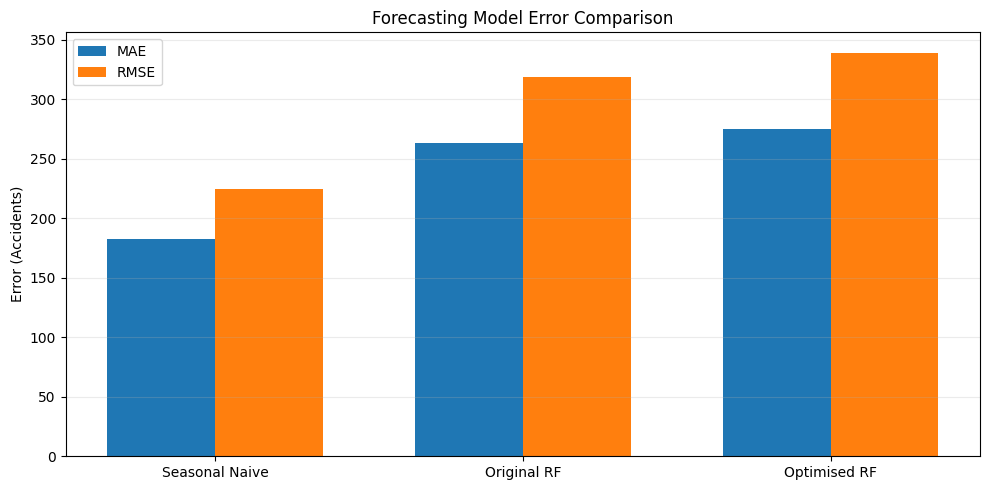

FINAL FORECASTING VISUALISATION COMPLETED


In [0]:

# Task 3 Part A - Cell 43
# Final Forecasting Performance Visualisation

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("TASK 3 - FINAL FORECASTING VISUALISATION")

# Prepare predictions from the three models
actual_df = (
    optimized_forecast_predictions
    .select("MonthDate", "Actual")
    .toPandas()
)

optimized_df = (
    optimized_forecast_predictions
    .select("MonthDate", "Prediction")
    .toPandas()
    .rename(columns={"Prediction": "OptimisedRF"})
)

original_df = (
    rf_forecast_results
    .select("MonthDate", "Prediction")
    .toPandas()
    .rename(columns={"Prediction": "OriginalRF"})
)

baseline_df = (
    baseline_predictions
    .select("MonthDate", "Prediction")
    .toPandas()
    .rename(columns={"Prediction": "SeasonalNaive"})
)

# Combine monthly predictions
chart_df = actual_df.merge(
    baseline_df, on="MonthDate"
).merge(
    original_df, on="MonthDate"
).merge(
    optimized_df, on="MonthDate"
)

chart_df["MonthDate"] = pd.to_datetime(chart_df["MonthDate"])
chart_df = chart_df.sort_values("MonthDate")

# Chart 1: Actual vs predicted accidents
plt.figure(figsize=(13, 6))

plt.plot(
    chart_df["MonthDate"],
    chart_df["Actual"],
    marker="o",
    linewidth=2,
    label="Actual Accidents"
)

plt.plot(
    chart_df["MonthDate"],
    chart_df["SeasonalNaive"],
    marker="s",
    linestyle="--",
    label="Seasonal Naive"
)

plt.plot(
    chart_df["MonthDate"],
    chart_df["OriginalRF"],
    marker="^",
    linestyle="--",
    label="Original Random Forest"
)

plt.plot(
    chart_df["MonthDate"],
    chart_df["OptimisedRF"],
    marker="d",
    linestyle=":",
    label="Optimised Random Forest"
)

plt.title("Monthly Traffic Accident Forecasting - 2023")
plt.xlabel("Month")
plt.ylabel("Number of Accidents")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 2: Model evaluation metrics
model_names = [
    "Seasonal Naive",
    "Original RF",
    "Optimised RF"
]

mae_values = [
    baseline_mae,
    rf_mae,
    optimized_mae
]

rmse_values = [
    baseline_rmse,
    rf_rmse,
    optimized_rmse
]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width / 2, mae_values, width, label="MAE")
plt.bar(x + width / 2, rmse_values, width, label="RMSE")

plt.xticks(x, model_names)
plt.ylabel("Error (Accidents)")
plt.title("Forecasting Model Error Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("FINAL FORECASTING VISUALISATION COMPLETED")
